# Proyecto Integrador: 2do avance Gradient Boosting, Stacking y Optimización

## Predicción de Churn de Clientes

Este notebook continúa el trabajo del 1er avance (donde exploramos y preparamos el dataset
`Churn_Modelling.csv` de FinanceGuard, con target `Exited` = si el cliente se dio de baja del banco).

## Objetivo:

- Comparar en igualdad de condiciones (misma partición estratificada y mismos folds de validación cruzada) el baseline de Regresión Logística frente a Random Forest, tres algoritmos de Gradient Boosting (XGBoost, LightGBM, CatBoost) y un ensamble por Stacking.
- Optimizar los hiperparámetros de XGBoost mediante Grid Search y Randomized Search, evaluando si el ajuste fino aporta una ganancia real y estable.
- Analizar métricas robustas al desbalanceo (ROC-AUC, PR-AUC, Recall, F1-Score) y extraer la importancia de variables del mejor modelo para guiar al equipo de retención.

## Pasos a seguir
1. *Librerias, Configuración y Funciones Genéricas:* Importar las Librerias a utilizar
2. *Carga de datos*, a partir del resultado del 1er avance CSV, se utilizará el CSV: `Churn_Modelling_limpio.csv`
3. *Comparar el Baseline con Random Forest, tres algoritmos de Gradient Boosting y un ensamble por Stacking*    
4. *Optimización de hiperparámetros*
5. *Tabla comparativa (validación cruzada, train)*
6. *Evaluación final sobre el conjunto de prueba (test)*
7. *Importancia de variables en el XGBoost optimizado*
8. *Conclusión y recomendación*



# 1 - Librerias, Configuración y Funciones Genéricas

Importar todas las herramientas necesarias

In [1]:
import time
import pandas as pd
import numpy as np
import warnings
import seaborn as sns
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from scipy.stats import randint, uniform
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score,f1_score, average_precision_score,make_scorer, confusion_matrix
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier



In [3]:
RANDOM_STATE = 42 #asegura que las particiones de datos y la inicialización de los árboles sean igual que avance 1

pd.set_option("display.max_columns", 50) #cantidad máxima de columnas que se muestran al imprimir un DataFrame

#dado un número v, le agrega el signo $ y en caso de ser negativo el signo lo pone delante del signo
#se utiliza en los gráficos con montos negativos
def fmt_usd(v):
    return f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"

#colores a utilizar en gráficos
colores_estrategicos = {
    "LogReg (Baseline)" : "#d853d0", 
    "Random Forest": "#5ee07a",  #Bagging
    "XGBoost": "#9ecae1",       #Boosting
    "LightGBM": "#6baed6",      #Boosting
    "CatBoost": "#2171b5" ,      #Boosting
    "Stacking": "#914141",
    "XGBoost (Optimizado)": "#c57d1e" ,  
    "XGBoost (GridSearch)":       "#a6512f",   # rojo ladrillo
    "XGBoost (RandomizedSearch)": "#e6732a",   # naranja
}

# orden en que se visualizarán los modelos en los gráficos (los que no estén en un gráfico se omiten)
orden = ["LogReg (Baseline)", "Random Forest", "XGBoost", "LightGBM", "CatBoost", "Stacking",
         "XGBoost (GridSearch)", "XGBoost (RandomizedSearch)"]



# 2 - Carga  de los datos

Cargamos el archivo resultante del 1er informe generado a partir de: CSV: *Churn_Modelling.csv*


In [ ]:
# Archivo generado en el 1er avance. Se usa una ruta relativa (en la misma carpeta que el notebook).
# Si todavía no existe, se reconstruye desde el CSV original con el mismo tratamiento del 1er avance.
import os
if os.path.exists("../data/Churn_Modelling_limpio.csv"):
    df = pd.read_csv("../data/Churn_Modelling_limpio.csv", encoding="UTF-8")
else:
    df = pd.read_csv("../data/Churn_Modelling.csv", encoding="UTF-8")
    df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
    df = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True, dtype=int)
df.head()


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


# 3 - Comparar el Baseline con Random Forest, tres algoritmos de Gradient Boosting y un ensamble por Stacking

Comparar en igualdad de condiciones (misma partición estratificada y mismos folds de validación cruzada) el baseline de Regresión Logística frente a Random Forest, tres algoritmos de Gradient Boosting (XGBoost, LightGBM, CatBoost) y un ensamble por Stacking.



## A) División en Predictoras (\[X\]), Objetivo (\[y\]) y  train/test split
Usamos `train_test_split`
separar los datos según el rol que juegan en la predicción: 

**[X] (Variables predictoras o características):** Son los datos de entrada, las pistas o las columnas que el modelo va a analizar para aprender. Se usa la mayúscula (\[X\]) porque suele ser una matriz (una tabla con muchas columnas). 

**[y] (Variable objetivo o target):** Es lo que quieres predecir, el resultado final o la respuesta correcta. Se usa la minúscula (\[y\]) porque suele ser una sola columna (un vector).

**En nuestro modelo:**
    [X] (Variables predictoras o características): todas las columnas menos Exited
    [y] (Variable objetivo o target): Exited

para la división de datos utilizando la librería scikit-learn, con estos parametros:
- X, y: los datos que modelo. 
- test_size=0.2: Indica que el 20% de los datos se reservará para el conjunto de prueba (X_test e y_test), mientras que el 80% restante se destinará de forma automática al conjunto de entrenamiento (X_train e y_train).
- random_state=RANDOM_STATE: Es una "semilla" de aleatoriedad. Al asignarle una variable o un número fijo (como 42), aseguras que la división de los datos sea reproducible. Cada vez que corras el código, los datos se mezclarán exactamente de la misma manera, evitando que los resultados de tu modelo cambien por puro azar.
- stratify=y:  Fuerza a que la división mantenga la misma proporción de clases en el conjunto de entrenamiento y en el de prueba que la que existe en el dataset original (y).

In [5]:
X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Churn rate:", y_train.mean().round(3))
print("Test: ", X_test.shape, "Churn rate:", y_test.mean().round(3))


Train: (8000, 11) Churn rate: 0.204
Test:  (2000, 11) Churn rate: 0.204


## B) Definición del Pipeline de Preprocesamiento 
 
A partir de los datos importados, los cuales ya vienen con:
- Dropeadas las columnas que no proveen comportamiento ("RowNumber","CustomerId","Surname")
- se transformaron `Geography` y `Gender` en variables 0/1 (one-hot con `drop_first=True`: `Geography_Germany`, `Geography_Spain` y `Gender_Male`). Todos los modelos las usan como entradas numéricas; ninguno las trata como categóricas nativas.

Se genera un *ColumnTransformer* el cual será utilizado posteriormente.

In [6]:
cat_cols = ["Geography_Germany", "Geography_Spain","Gender_Male"]
bin_cols = ["HasCrCard", "IsActiveMember"]
num_cols = [c for c in X.columns if c not in cat_cols + bin_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", "passthrough", cat_cols),
        ("bin", "passthrough", bin_cols),
    ]
)

print("Numéricas continuas:", num_cols)
print("Categóricas:", cat_cols)
print("Binarias:", bin_cols)

Numéricas continuas: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
Categóricas: ['Geography_Germany', 'Geography_Spain', 'Gender_Male']
Binarias: ['HasCrCard', 'IsActiveMember']


## C) Configuración de la Validación Cruzada y métricas especializadas

### - Configuración de la Validación Cruzada (CV) 
Como `Exited` está desbalanceado (~20% positivos), usamos `StratifiedKFold`: cada fold
mantiene aproximadamente la misma proporción de churn que el dataset completo. 
- n_splits=5: Divide el conjunto de datos en 5 partes (pliegues o folds). El modelo se entrenará 5 veces separadas. En cada iteración, usará 4 partes para el entrenamiento y 1 parte restante para la validación (prueba)
- shuffle=True: Aplica un barajado aleatorio de las muestras de cada clase antes de realizar los cortes. 
- random_state=RANDOM_STATE: Establece una semilla numérica fija para controlar la aleatoriedad del barajado. Garantiza la reproducibilidad, lo que significa que el algoritmo generará exactamente las mismas divisiones cada vez que ejecutes el código

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### - Configuración de Métricas

Las métricas que vamos a analizar en todos los modelos: 
- **Accuracy (Exactitud)**: Mide el porcentaje total de aciertos del modelo (cantidad de transacciones que se clasificaron corectamente dividido entre el total de transacciones).
- **Precision**: Responde a la pregunta: De todo lo que el modelo clasificó como positivo, ¿cuánto era realmente positivo? 
- **Recall (Sensibilidad)**: Responde la pregunta: De todo lo que era positivo en la realidad, ¿cuánto logró detectar el modelo? 
- **F1-Score**: Es la media armónica entre Precision y Recall; proporciona un único valor de balance cuando ambas métricas son críticas y existe un fuerte desbalance de clases.
- **ROC-AUC** Mide la capacidad del modelo para ordenar o separar las clases, evaluando el balance general entre detectar positivos (Verdaderos Positivos) y evitar falsas alarmas (Falsos Positivos) 
- **PR-AUC**  Mide el rendimiento del modelo enfocándose exclusivamente en la clase positiva (el balance entre Precision y Recall)
- **negocio_scorer** : métrica personalizada orientada al negocio, traduce el rendimiento técnico del modelo (matriz de confusión) en impacto económico real

En un problema de churn, Recall (detectar a los clientes que realmente se van a ir), F1-Score (para mantener un equilibrio con los falsos positivos)  y ROC-AUC (qué tan bien separa el modelo ambas clases en general) suelen ser más importantes que el Accuracy solo, porque el desbalanceo de clases
puede inflar el Accuracy incluso con un modelo poco útil.

#### - Métrica Personalizada

Es una métrica orientada a negocio que traduce el rendimiento técnico del modelo (matriz de confusión) en impacto económico real, penalizando monetariamente los errores de predicción y recompensando los aciertos según las prioridades financieras de la empresa."

In [8]:
#  DEFINIR  MÉTRICA DE NEGOCIO PERSONALIZADA
def metrica_negocio_fun(y_true, y_pred, ganancia_tp=100, perdida_fn=150,
                        costo_fp=20, normalizar=False):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    beneficio = tp * ganancia_tp - fn * perdida_fn - fp * costo_fp
    return beneficio / len(y_true) if normalizar else beneficio

negocio_scorer = make_scorer(metrica_negocio_fun, greater_is_better=True, response_method="predict")


#### - Configuración de un sistema de evaluación multímétrica

- **Métricas estándar (accuracy, precision, recall, f1 )**: Monitorean los aciertos, el control de falsas alarmas y la capacidad de detección.
- **Métricas robustas (roc_auc, pr_auc)**: Evalúan la calidad de las probabilidades del modelo. Nota técnica: En Scikit-Learn, la cadena "average_precision" es la forma estándar de calcular el PR-AUC.
- **Métrica personalizada (business_metric)**: Integra tu función de negocio (negocio_scorer). Esto significa que el proceso registrará cuánto dinero (utilidad neta) generaría cada combinación de parámetros.


In [9]:

scoring = {
    # métricas standar
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    # Robustas para datos desbalanceados
    "roc_auc": "roc_auc",                 # Capacidad global de separación
    "pr_auc": "average_precision",        # PR-AUC enfocado en la clase minoritaria (Crucial para desbalance)
    # Métrica de impacto económico real
    "business_metric": negocio_scorer
}


### - Función que retorna los resultados simplificados y limpios 

Cuando ejecutas una validación cruzada con múltiples métricas, **Scikit-Learn** devuelve un diccionario gigante con los resultados de cada una de las iteraciones (folds). 
Esta función simplifica y limpia esos resultados.
- ¿Cómo funciona? Usa una comprensión de diccionario para iterar sobre las métricas que definiste en scoring.
- cv_results[f"test_{m}"]: Accede a la lista de puntuaciones obtenidas en el set de prueba para la métrica m en cada fold.
- .mean(): Calcula el promedio numérico de esos folds para entregarte un único valor final por métrica.
- m : ...: Define que el nombre limpio (sin el test_) será la clave del diccionario, y el promedio calculado será su valor.


In [10]:

def resumen_cv(cv_results):
    res = {m: cv_results[f"test_{m}"].mean() for m in scoring}
    res["roc_auc_std"] = cv_results["test_roc_auc"].std()
    return res

## D) Entrenamiento y comparación de modelos base en Validación Cruzada

Entrenaremos y compara estos cinco modelos, con configuraciones razonables para tener
un punto de comparación:

- **Regresión Logística** (Baseline Avance 1)
- **Random Forest**: modelo de bagging, referencia clásica antes de pasar a boosting.
- **XGBoost**: boosting secuencial, muy usado en la industria por su buen desempeño general.
- **LightGBM**: boosting más rápido en datasets grandes, crece los árboles por hojas en vez de
  por niveles.
- **CatBoost**: boosting pensado para manejar bien variables categóricas. En este proyecto `Geography` y `Gender` ya llegan codificadas como 0/1, por lo que CatBoost no aprovecha esa ventaja.

### Configuración
- Random Forest: Configurado con 300 árboles y profundidad máxima de 8 (Bagging de referencia).
- XGBoost, LightGBM y CatBoost: Configurados con parámetros de Boosting comparables (200 árboles/iteraciones, profundidad de 4 y tasa de aprendizaje de 0.1) para que la competencia sea justa.
- Parámetros de control: Usan RANDOM_STATE para asegurar que los experimentos sean reproducibles y un solo hilo por modelo (`n_jobs=1`, `thread_count=1` en CatBoost): el paralelismo se hace en `cross_validate` (`n_jobs=-1`). Así los tiempos de entrenamiento son comparables entre modelos y los hilos no compiten entre sí.



In [11]:
modelos_base = {
    "LogReg (Baseline)": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier( # Configurado con 300 árboles y profundidad máxima de 8 (Bagging de referencia)
        n_estimators=300, max_depth=8, 
        random_state=RANDOM_STATE, n_jobs=1
    ),
    "XGBoost": XGBClassifier(       #200 árboles/iteraciones, profundidad de 4 y tasa de aprendizaje de 0.1
        n_estimators=200, max_depth=4, learning_rate=0.1,
        eval_metric="logloss", 
        random_state=RANDOM_STATE, n_jobs=1
    ),
    "LightGBM": LGBMClassifier(     #200 árboles/iteraciones, profundidad de 4 y tasa de aprendizaje de 0.1
        n_estimators=200, max_depth=4, learning_rate=0.1,
        random_state=RANDOM_STATE, n_jobs=1, verbose=-1
    ),
    "CatBoost": CatBoostClassifier( #200 árboles/iteraciones, profundidad de 4 y tasa de aprendizaje de 0.1
        iterations=200, depth=4, learning_rate=0.1,
        random_state=RANDOM_STATE, verbose=False, thread_count=1
    ),
}

### Proceso
Cada uno va dentro de un `Pipeline` con el mismo preprocesamiento, y lo evaluamos con
`cross_validate` usando el `StratifiedKFold` definido, para que la comparación sea
sobre las mismas particiones de datos.

### Entrenamiento

Durante el entrenamiento tomaremos los tiempos, asi podremos utilizar este valor como punto de comparación entre modelos

In [12]:
resultados_cv = {}

for nombre, modelo in modelos_base.items():
    pipe = Pipeline([("prep", preprocess), ("clf", modelo)])
    
    # 1. Medir el tiempo real de espera (reloj de pared) para este modelo específico
    start_wall = time.time()
    
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=-1, error_score="raise")
    
    end_wall = time.time()
    wall_time_total = end_wall - start_wall
    
    # 2. Extraer las métricas nativas de tiempo de Scikit-Learn
    fit_time_total = sum(cv_res["fit_time"])        # Tiempo total invertido en entrenar todos los folds
    fit_time_mean = cv_res["fit_time"].mean()       # Tiempo promedio por cada fold
    score_time_total = sum(cv_res["score_time"])    # Tiempo total invertido en evaluar/predecir
    
    # 3. Guardar el resumen original y añadir las nuevas métricas de tiempo
    resultados_cv[nombre] = resumen_cv(cv_res)
    resultados_cv[nombre]["fit_time_total"] = fit_time_total
    resultados_cv[nombre]["fit_time_mean"] = fit_time_mean
    resultados_cv[nombre]["wall_time_total"] = wall_time_total
    resultados_cv[nombre]["score_time_total"] = score_time_total  # Crucial para entornos en producción (latencia)
    
    # 4. Print actualizado con el rendimiento de tiempo integrado
    print(f"✅ {nombre} listo | ROC-AUC CV: {resultados_cv[nombre]['roc_auc']:.4f} (±{resultados_cv[nombre]['roc_auc_std']:.4f}) | T. Entrenamiento: {fit_time_total:.2f}s (Espera real: {wall_time_total:.2f}s)")

✅ LogReg (Baseline) listo | ROC-AUC CV: 0.7628 (±0.0199) | T. Entrenamiento: 2.00s (Espera real: 39.51s)
✅ Random Forest listo | ROC-AUC CV: 0.8594 (±0.0088) | T. Entrenamiento: 69.35s (Espera real: 44.23s)
✅ XGBoost listo | ROC-AUC CV: 0.8609 (±0.0128) | T. Entrenamiento: 16.58s (Espera real: 4.28s)
✅ LightGBM listo | ROC-AUC CV: 0.8603 (±0.0115) | T. Entrenamiento: 6.22s (Espera real: 2.33s)
✅ CatBoost listo | ROC-AUC CV: 0.8683 (±0.0119) | T. Entrenamiento: 23.53s (Espera real: 5.41s)


### Tabla comparativa de resultados

In [13]:
df_comparativa = pd.DataFrame(resultados_cv).T
df_comparativa.index = df_comparativa.index.str.replace("\n", " ", regex=False)

preferidas = ["business_metric", "pr_auc"]
columna_orden = next((c for c in preferidas if c in df_comparativa.columns), None)
if columna_orden is None:
    raise KeyError(f"Ninguna de {preferidas} está en {list(df_comparativa.columns)}")

df_comparativa = df_comparativa.sort_values(columna_orden, ascending=False)

print(f"--- TABLA COMPARATIVA (ordenada por {columna_orden}) ---")
print(df_comparativa.round(4).to_string())



--- TABLA COMPARATIVA (ordenada por business_metric) ---
                   accuracy  precision  recall      f1  roc_auc  pr_auc  business_metric  roc_auc_std  fit_time_total  fit_time_mean  wall_time_total  score_time_total
LightGBM             0.8609     0.7382  0.4908  0.5895   0.8603  0.6918         -10032.0       0.0115          6.2211         1.2442           2.3297            2.9588
XGBoost              0.8626     0.7519  0.4853  0.5897   0.8609  0.6937         -10390.0       0.0128         16.5793         3.3159           4.2808            1.8128
CatBoost             0.8615     0.7532  0.4755  0.5828   0.8683  0.7087         -11162.0       0.0119         23.5344         4.7069           5.4113            1.4714
Random Forest        0.8589     0.7940  0.4147  0.5448   0.8594  0.6880         -15800.0       0.0088         69.3507        13.8701          44.2303            7.1463
LogReg (Baseline)    0.8104     0.5961  0.2135  0.3141   0.7628  0.4688         -32440.0       0.0199  

### Gráfico comparativo de las métricas de rendimiento


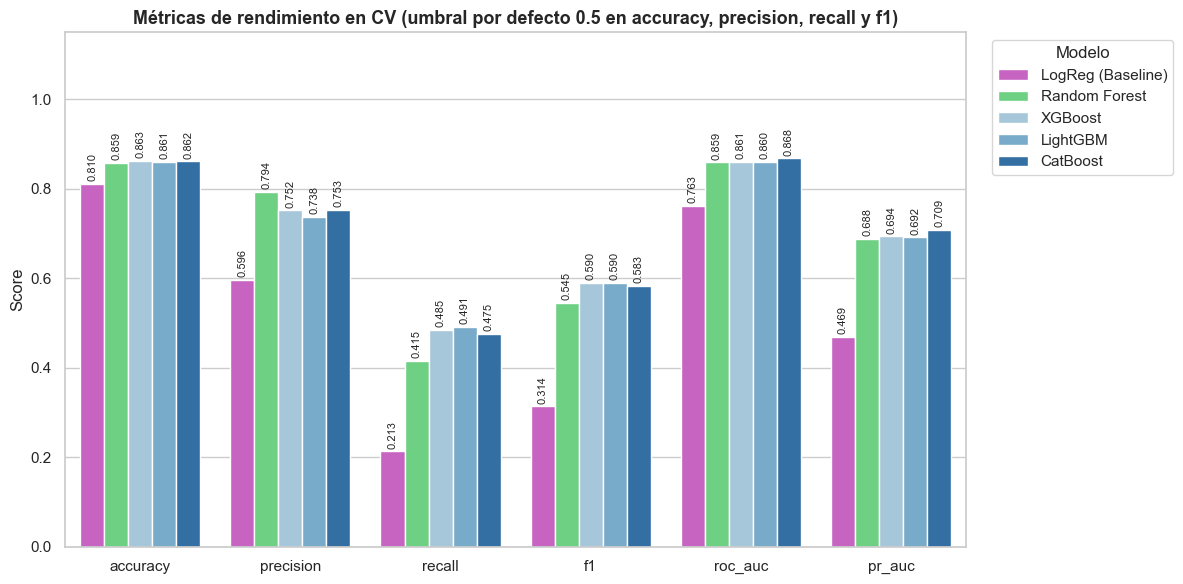

In [14]:

df_ml = df_comparativa.copy()
df_ml.index = df_ml.index.str.replace("\n", " ", regex=False)
df_ml = df_ml.sort_values("roc_auc", ascending=False)

metricas_ml = ["accuracy", "precision", "recall", "f1","roc_auc", "pr_auc"]
metricas_existentes = [m for m in metricas_ml if m in df_ml.columns]
faltantes = [m for m in ["accuracy", "precision", "recall", 'f1' , "roc_auc", "pr_auc"] if m not in df_ml.columns]
if faltantes:
    print(f"Aviso: no están en la tabla {faltantes}. Columnas disponibles: {list(df_ml.columns)}")

df_long = (df_ml[metricas_existentes]
           .rename_axis("Modelo").reset_index()
           .melt(id_vars="Modelo", var_name="Métrica", value_name="Score"))

# Paleta construida desde los modelos presentes (no depende de claves fijas)
modelos = [m for m in orden if m in df_ml.index]
colores = colores_estrategicos 

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(ax=ax, data=df_long, x="Métrica", y="Score", hue="Modelo",
            hue_order=modelos, palette=colores)

for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.3f}" for v in cont.datavalues],
                 fontsize=8, padding=2, rotation=90)

ax.set_ylim(0, 1.15)
ax.set_title("Métricas de rendimiento en CV (umbral por defecto 0.5 en accuracy, precision, recall y f1)",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Los modelos de ensamble tienen valores similares en casi todas las métricas. Se diferencian la regresión logística (baseline), con un *recall* de ~0,213 y un F1 de ~0,314 muy por debajo del resto, y *Random Forest*, que tiene mayor precisión y menor *recall* que los boostings. Cabe destacar que mientras las métricas de clasificación dura dependen del umbral de 0.5 fijado, ROC-AUC y PR-AUC evalúan el ordenamiento global de las probabilidades y son completamente independientes de dicho umbral.

### Gráfico comparativo de la Métrica de Negocio Personalizada
Recordemos que nuestra métrica personalizada, representa *El Costo de los Falsos Positivos y Falsos Negativos* (Matriz de Confusión Financiera)
- Ganamos $100 por detectar un caso positivo correctamente (TP)
- Perdemos $150 si se nos escapa un positivo (FN)
- Perdemos $20 por molestar a un cliente con un falso positivo (FP)
    


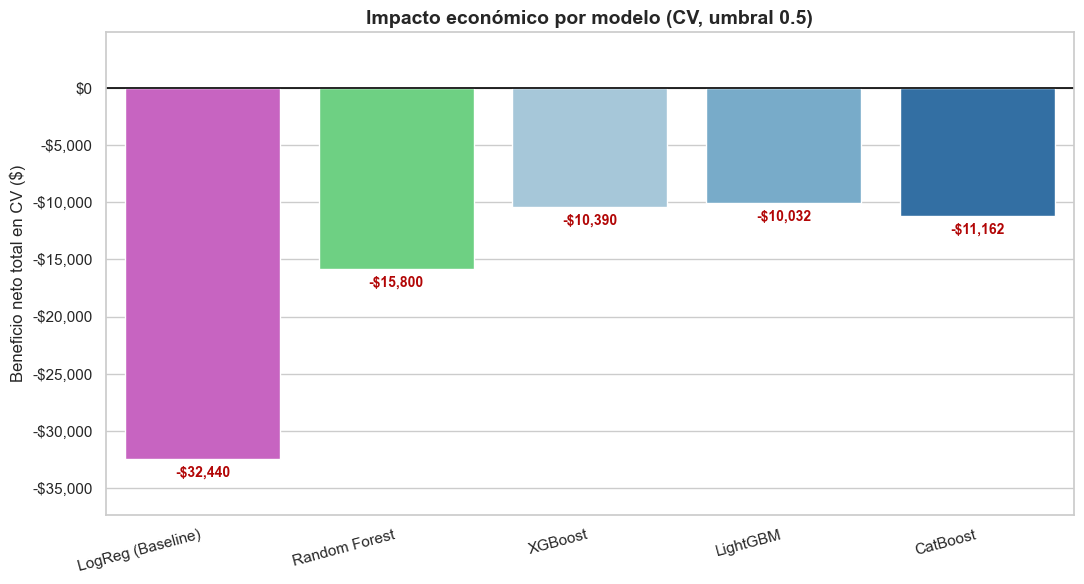

In [15]:

df_b = df_comparativa.copy()
df_b.index = df_b.index.str.replace("\n", " ", regex=False)

# Opción B: orden fijo del informe (bagging, boosting, stacking, optimizados)
df_b = df_b.loc[[m for m in orden if m in df_b.index]]

paleta = {m: colores_estrategicos.get(m, "#999999") for m in modelos}

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(ax=ax, x=df_b.index, y=df_b["business_metric"], order=modelos,
            hue=df_b.index, hue_order=modelos, palette=paleta, legend=False)

for p in ax.patches:
    h = p.get_height()
    if pd.notna(h):
        pos = h >= 0
        ax.annotate(f"${h:,.0f}" if pos else f"-${abs(h):,.0f}",
                    (p.get_x() + p.get_width() / 2., h),
                    ha="center", va="bottom" if pos else "top",
                    fontsize=10, fontweight="bold",
                    color="#1a5f7a" if pos else "#b20606",
                    xytext=(0, 5 if pos else -5), textcoords="offset points")

ax.axhline(0, color="black", linewidth=1.2)
ax.set_title("Impacto económico por modelo (CV, umbral 0.5)", fontsize=14, fontweight="bold")
ax.set_ylabel("Beneficio neto total en CV ($)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(
    lambda x, _: f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}"))
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")

lo, hi = df_b["business_metric"].min(), df_b["business_metric"].max()
margen = (max(hi, 0) - min(lo, 0)) * 0.15
ax.set_ylim(min(lo, 0) - margen, max(hi, 0) + margen)

plt.tight_layout()
plt.show()

Estos montos corresponden al umbral de decisión por defecto (0.5), con el que los modelos dejan escapar más de la mitad de los casos positivos (*recall* ≈ 0,48) y cada positivo no detectado cuesta 150. Miden el efecto del punto de corte y no la calidad del modelo: no significa que los modelos no sirvan, sino que el umbral debe ajustarse a los costos del negocio

## E) Ensamble por Stacking

## Stacking (o Stacked Generalization) 
es una técnica de aprendizaje en ensamble de Machine Learning que consiste en combinar las predicciones de varios modelos diferentes utilizando un nuevo modelo (llamado meta-modelo) para generar el resultado final

Un Stacking combina varios modelos (nivel 1) entrenando un modelo adicional (meta-learner) que
aprende a **pesar las predicciones** de esos modelos, en vez de simplemente promediarlas. 

La idea es que el meta-learner puede capturar en qué situaciones conviene confiar más en un
booster u otro.

- **Nivel 1**: XGBoost + LightGBM + CatBoost (los tres boosters).
    - eval_metric="logloss" Es una métrica de rendimiento para clasificadores que penaliza severamente las predicciones que son erróneas y seguras al mismo tiempo.
      
      Si el modelo está un 99% seguro de que un cliente se va a quedar, pero el cliente abandona el banco (Falso Negativo), logloss le aplicará un castigo enorme.
    - cantidad de arboles: 200
    - profundidad: 4
- **Meta-learner**: regresión logística **regularizada** (`LogisticRegression` con
  penalización L2 por default), porque es un modelo simple y estable para combinar unas pocas
  probabilidades sin sobreajustar.

`StackingClassifier` de sklearn ya usa validación cruzada interna para generar las predicciones
de **Nivel 1** que alimentan al **Meta-learner**, evitando que el **Meta-learner** "vea" predicciones
hechas sobre los mismos datos con los que se entrenaron los boosters.

In [16]:
# 1. Stacking: un hilo por modelo, paralelismo solo en cross_val_predict

stacking = StackingClassifier(
    estimators=[
        ("xgb", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                              eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
        ("lgbm", LGBMClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
        ("cat", CatBoostClassifier(iterations=200, depth=4, learning_rate=0.1,
                                   random_state=RANDOM_STATE, verbose=False, thread_count=1)),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv,
    n_jobs=1,
)

pipe_stack = Pipeline([("prep", preprocess), ("clf", stacking)])

# 1. Medir el tiempo real de espera (reloj de pared) para el Stacking
start_wall_stack = time.time()

cv_res_stack = cross_validate(pipe_stack, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

end_wall_stack = time.time()
wall_time_total_stack = end_wall_stack - start_wall_stack

# 2. Extraer las métricas de tiempo calculadas por Scikit-Learn
fit_time_total_stack = sum(cv_res_stack["fit_time"])        # Tiempo total acumulado de entrenamiento
fit_time_mean_stack = cv_res_stack["fit_time"].mean()       # Tiempo promedio por fold
score_time_total_stack = sum(cv_res_stack["score_time"])    # Tiempo total de predicción

# 3. Guardar el resumen analítico e integrar la estructura de tiempos
resultados_cv["Stacking"] = resumen_cv(cv_res_stack)
resultados_cv["Stacking"]["fit_time_total"] = fit_time_total_stack
resultados_cv["Stacking"]["fit_time_mean"] = fit_time_mean_stack
resultados_cv["Stacking"]["wall_time_total"] = wall_time_total_stack
resultados_cv["Stacking"]["score_time_total"] = score_time_total_stack

# 4. Mensajes por pantalla unificados
print(f"✓ Stacking listo               | ROC-AUC CV: {resultados_cv['Stacking']['roc_auc']:.4f} (±{resultados_cv['Stacking']['roc_auc_std']:.4f}) | T. Entrenamiento: {fit_time_total_stack:.2f}s (Espera real: {wall_time_total_stack:.2f}s)")
print("✅ Stacking preparado")



✓ Stacking listo               | ROC-AUC CV: 0.8674 (±0.0119) | T. Entrenamiento: 433.78s (Espera real: 91.21s)
✅ Stacking preparado


### Gráfico comparativo de las métricas de rendimiento


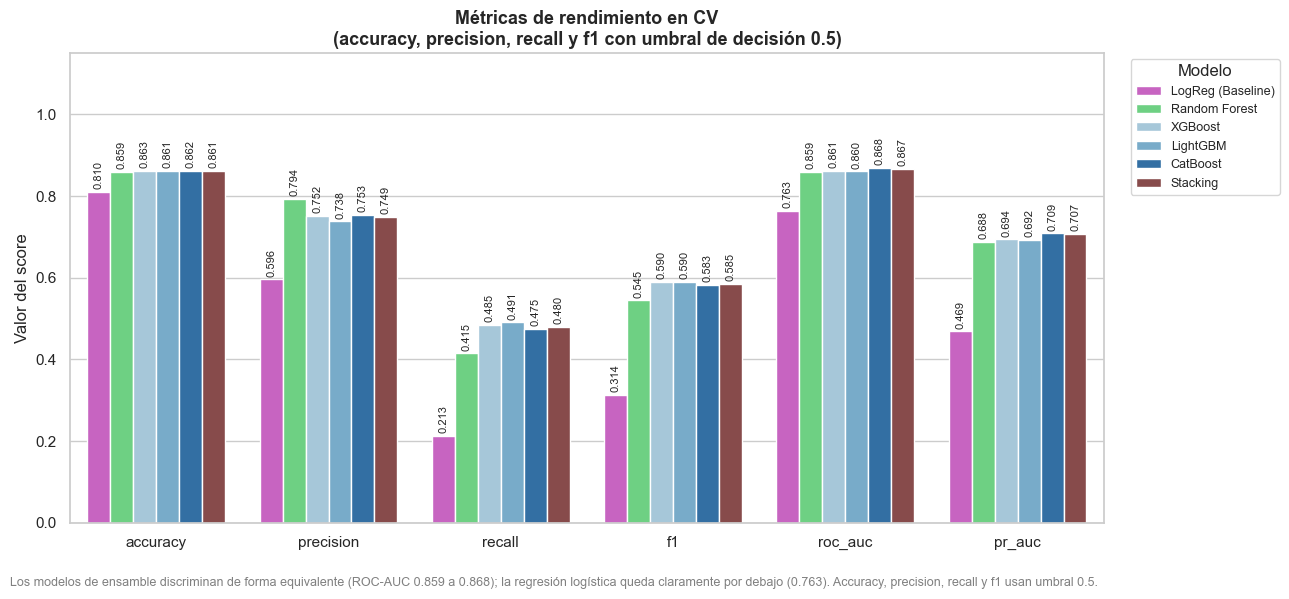

In [17]:
df_completo = pd.DataFrame(resultados_cv).T
df_ml = df_completo.copy()
df_ml.index = df_ml.index.str.replace("\n", " ", regex=False)


metricas_ml = ["accuracy", "precision", "recall", "f1","roc_auc", "pr_auc"]
metricas_existentes = [m for m in metricas_ml if m in df_ml.columns]
faltantes = [m for m in metricas_ml if m not in df_ml.columns]
if faltantes:
    print(f"Aviso: no están en la tabla {faltantes}. Columnas disponibles: {list(df_ml.columns)}")

df_long = (df_ml[metricas_existentes]
           .rename_axis("Modelo").reset_index()
           .melt(id_vars="Modelo", var_name="Métrica", value_name="Score"))

# Colores: los de tu diccionario (con "\n" o "/n" normalizados), gris si falta alguno
colores_limpios = {k.replace("\n", " ").replace("/n", " "): v for k, v in colores_estrategicos.items()}

modelos = [m for m in orden if m in df_ml.index]
paleta = {m: colores_limpios.get(m, "#999999") for m in modelos}

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(ax=ax, data=df_long, x="Métrica", y="Score", hue="Modelo",
            hue_order=modelos, palette=paleta)

# Valores sobre cada barra
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.3f}" for v in cont.datavalues],
                 fontsize=8, padding=2, rotation=90)

ax.set_title("Métricas de rendimiento en CV\n(accuracy, precision, recall y f1 con umbral de decisión 0.5)",
             fontsize=13, fontweight="bold")
ax.set_ylim(0, 1.15)
ax.set_ylabel("Valor del score")
ax.set_xlabel("")
ax.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
fig.text(0.01, 0.01,
         "Los modelos de ensamble discriminan de forma equivalente (ROC-AUC 0.859 a 0.868); la regresión logística queda claramente por debajo (0.763). Accuracy, precision, recall y f1 usan umbral 0.5.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### Gráfico comparativo de la Métrica de Negocio Personalizada

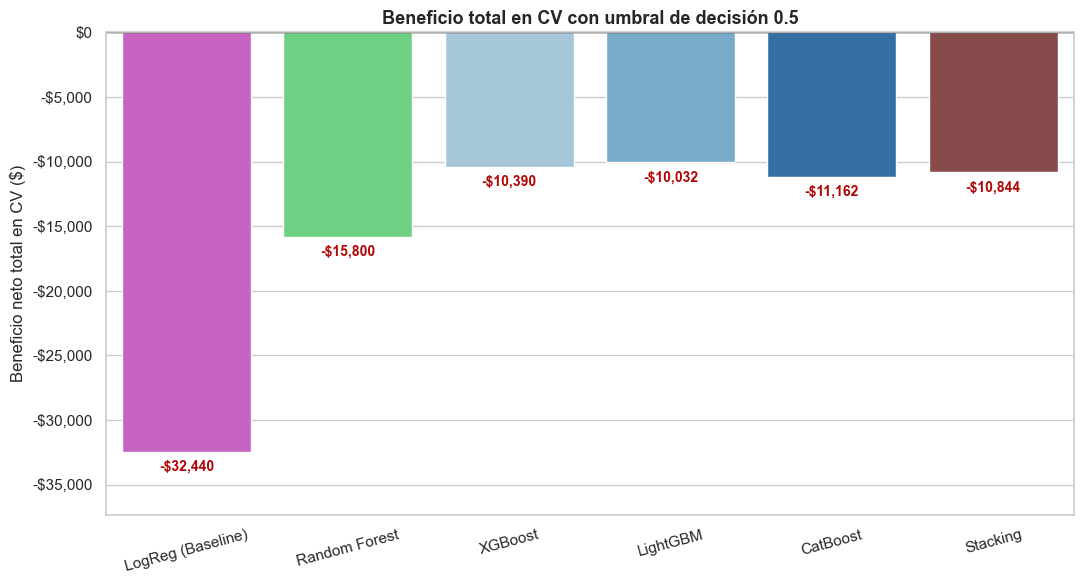

In [18]:
df_b = df_completo.copy()
df_b.index = df_b.index.str.replace("\n", " ", regex=False)
df_b = df_b.sort_values("business_metric", ascending=False)
df_b = df_b.loc[[m for m in orden if m in df_b.index]]

colores_limpios = {k.replace("\n", " "): v for k, v in colores_estrategicos.items()}
paleta = {m: colores_limpios.get(m, "#999999") for m in df_b.index}

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(ax=ax, x=df_b.index, y=df_b["business_metric"],
            hue=df_b.index, palette=paleta, legend=False)

for p in ax.patches:
    h = p.get_height()
    if pd.notna(h):
        # etiquetas de las barras
        ax.annotate(fmt_usd(h), (p.get_x() + p.get_width() / 2., h),
            ha="center", va="top" if h < 0 else "bottom",
            fontsize=10, fontweight="bold",
            color="#b20606" if h < 0 else "#1a5f7a",   # rojo si es negativo, azul si es positivo
            xytext=(0, -6 if h < 0 else 6), textcoords="offset points")
ax.set_xticklabels([t.get_text().replace("Stacking (", "Stacking\n(") for t in ax.get_xticklabels()])      
ax.axhline(0, color="black", linewidth=1)
ax.set_ylim(min(df_b["business_metric"].min() * 1.15, 0), max(df_b["business_metric"].max() * 1.15, 0))
ax.set_title("Beneficio total en CV con umbral de decisión 0.5", fontsize=13, fontweight="bold")
ax.set_ylabel("Beneficio neto total en CV ($)")
ax.set_xlabel("")
# eje Y
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: fmt_usd(x)))
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

# 4 - Optimización de hiperparámetros

## A) Elegir modelo a optimizar
Evaluaremos los resultados de:
- Compromiso entre Rendimiento y Tiempo de Entrenamiento de cada modelo
- Métricas de rendimiento en CV  - calculadas en el punto anterior
- Beneficio total en CV - calculada en el punto anterior - metríca personalizada

### Gráfico de Compromiso entre Rendimiento y Tiempo de Entrenamiento
Se comparan los tiempos de entrenamiento de todos los modelos (suma de los 5 folds de la validación cruzada, con un hilo por modelo). Estos valores son parte de la decisión de qué modelo optimizar, junto con las métricas de rendimiento y la métrica de negocio.

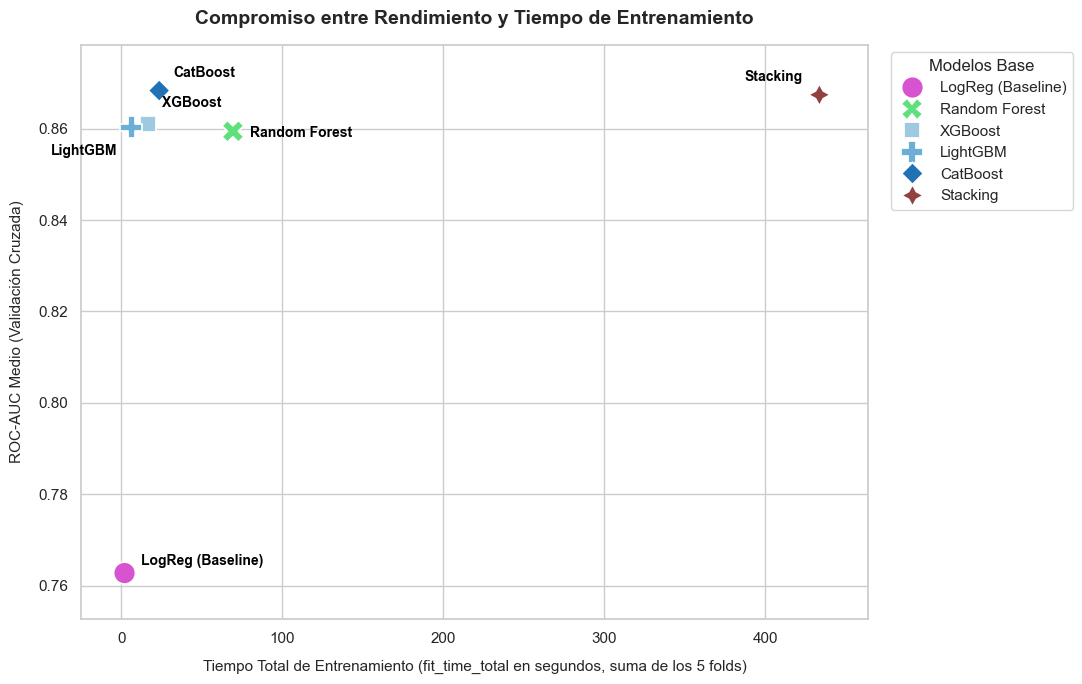

In [19]:
# 1. Convertir el diccionario de resultados en un DataFrame de Pandas
df_resultados = pd.DataFrame(resultados_cv).T.reset_index()
df_resultados.rename(columns={'index': 'Modelo'}, inplace=True)

# 2. Configurar el estilo del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 7))

# 3. Gráfico de dispersión con la paleta de colores del informe
scatter = sns.scatterplot(
    data=df_resultados,
    x="fit_time_total",
    y="roc_auc",
    hue="Modelo",
    style="Modelo",
    s=250,
    palette=colores_estrategicos
)

# 4. Etiquetas con desplazamiento en puntos (no dependen de la escala de los ejes).
#    (dx, dy, alineación horizontal)
offsets = {
    "LogReg (Baseline)": (12, 6, "left"),
    "Random Forest":     (12, -4, "left"),
    "XGBoost":           (10, 12, "left"),     # arriba a la derecha de su marcador
    "LightGBM":          (-10, -20, "right"),  # abajo a la izquierda, para no pisar a XGBoost
    "CatBoost":          (10, 10, "left"),
    "Stacking":          (-12, 10, "right"),
}
for _, fila in df_resultados.iterrows():
    dx, dy, ha = offsets.get(fila["Modelo"], (8, 8, "left"))
    plt.annotate(fila["Modelo"], (fila["fit_time_total"], fila["roc_auc"]),
                 xytext=(dx, dy), textcoords="offset points", ha=ha,
                 fontsize=10, fontweight="bold", color="black")

# 5. Personalizar ejes y títulos
plt.title("Compromiso entre Rendimiento y Tiempo de Entrenamiento", fontsize=14, pad=15, weight='bold')
plt.xlabel("Tiempo Total de Entrenamiento (fit_time_total en segundos, suma de los 5 folds)", fontsize=11, labelpad=10)
plt.ylabel("ROC-AUC Medio (Validación Cruzada)", fontsize=11, labelpad=10)

plt.xlim(-25, df_resultados["fit_time_total"].max() + 30)
plt.ylim(df_resultados["roc_auc"].min() - 0.01, df_resultados["roc_auc"].max() + 0.01)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="Modelos Base")
plt.tight_layout()
plt.show()


### Gráfico de Métricas de rendimiento en CV


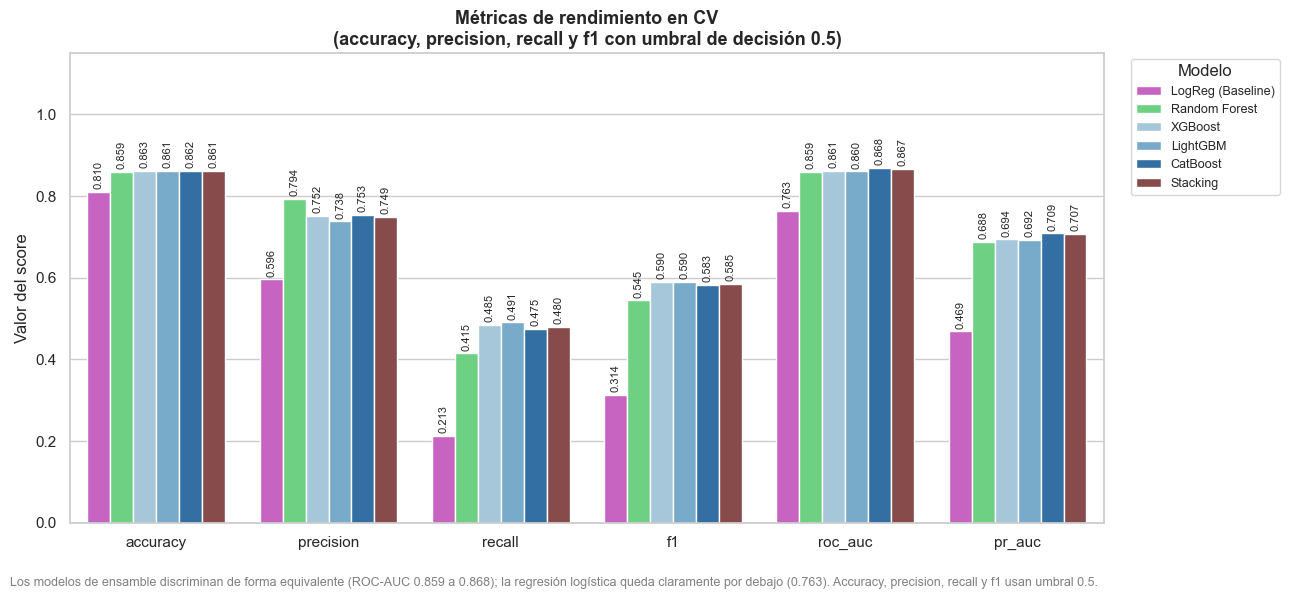

### Gráfico comparativo de la métrica de Negocio Personalizada en CV


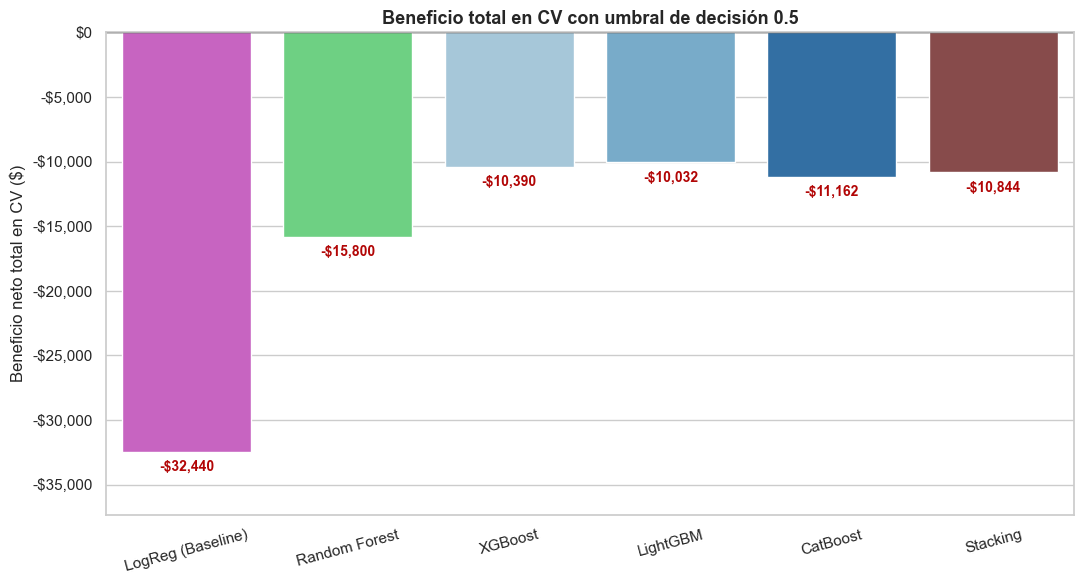

### Selección del modelo a optimizar

Se compararon seis modelos con validación cruzada de 5 folds: una regresión logística como baseline, Random Forest, XGBoost, LightGBM, CatBoost y un stacking de los tres boostings.

**1. Todos los ensambles superan claramente al baseline.** La regresión logística obtiene un ROC-AUC de 0,763 y un PR-AUC de 0,469, frente a 0,859–0,868 y 0,688–0,709 de los ensambles. Su recall con el umbral 0,5 es de 0,21 y su pérdida total en validación cruzada es la mayor (−32.440 dólares, el triple que la de los boostings).

**2. Entre los ensambles, la capacidad de discriminación es equivalente.** El ROC-AUC va de 0,859 a 0,868 (menos de 0,01 de diferencia) y el recall con umbral 0,5 es de ~0,48 en los boostings. CatBoost y el stacking tienen el valor más alto (0,868 y 0,867), pero la ventaja sobre XGBoost (0,861) es de apenas 0,007, menor que el desvío entre folds (≈0,012).

**3. La métrica de negocio.** Todos los ensambles pierden entre 10.000 y 16.000 dólares, porque dejan escapar más de la mitad de los positivos. Es el efecto del umbral 0.5 y no mide la calidad del modelo, por lo que no se usa para elegir (en la sección 7 se calcula el umbral óptimo y se verifica si la elección cambia).

**4. El costo de entrenamiento.** Tiempos medidos con un hilo por modelo (suma de los 5 folds; varían entre ejecuciones, por lo que se toman como orden de magnitud):

| Modelo | Tiempo total de CV | ROC-AUC (CV) |
|---|---|---|
| LightGBM | 5,2 s | 0,860 |
| XGBoost | 12,5 s | 0,861 |
| CatBoost | 22,0 s | 0,868 |
| Random Forest | 53,4 s | 0,859 |
| Stacking | 254,6 s | 0,867 |

El stacking tarda unas 20 veces más que XGBoost sin una mejora distinguible, por lo que queda descartado. CatBoost tarda casi el doble que XGBoost para una diferencia de 0,007 en ROC-AUC, también dentro del ruido entre folds. LightGBM es el más rápido, pero la diferencia con XGBoost es de segundos (5,2 s frente a 12,5 s) y su rendimiento es el mismo.

**Decisión.** XGBoost, LightGBM y CatBoost rinden de forma equivalente y su costo de entrenamiento es bajo (menos de 25 s para los 5 folds), mientras que el stacking y Random Forest son más caros sin ventaja. Se selecciona **XGBoost** para la etapa de optimización de hiperparámetros entre las alternativas equivalentes.


## B) Optimización de XGBoost 


### Búsqueda de hiperparámetros
**Estrategia de búsqueda de mejores hiperparámetros**

Se aplicaron dos estrategias complementarias sobre XGBoost, ambas con validación cruzada estratificada:
- GridSearchCV (Búsqueda exhaustiva en grilla): evalúa todas las combinaciones posibles de un conjunto discreto de hiperparámetros (n_estimators, max_depth, learning_rate).
- RandomizedSearchCV (Búsqueda aleatoria sobre distribuciones): muestrea un número fijo de combinaciones (n_iter=12) sobre distribuciones continuas y discretas, permitiendo explorar también regularización por submuestreo (subsample, colsample_bytree) con un costo computacional controlado.

- Criterio de selección: `scoring="roc_auc"`, independiente del umbral de decisión.
- Parámetros
    - refit=True: tanto GridSearchCV como RandomizedSearchCV re-entrenan automáticamente el mejor pipeline (best_estimator_) sobre todo X_train, y_train una vez hallada la mejor combinación en validación cruzada.


In [20]:
pipe_xgb = Pipeline([
    ("prep", preprocess),
    ("clf", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)),
])

# 1. GridSearchCV
param_grid = {
    "clf__n_estimators": [150, 300],
    "clf__max_depth": [3, 5],
    "clf__learning_rate": [0.05, 0.10],
}

grid = GridSearchCV(
    pipe_xgb, param_grid=param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True
)
grid.fit(X_train, y_train)
print("Mejores hiperparámetros (GridSearchCV):", grid.best_params_)
print(f"Mejor ROC-AUC (CV GridSearch): {grid.best_score_:.4f}\n")

# 2. RandomizedSearchCV
param_dist = {
    "clf__n_estimators": randint(150, 350),
    "clf__max_depth": randint(3, 6),
    "clf__learning_rate": uniform(0.03, 0.10),
    "clf__subsample": uniform(0.75, 0.25),
    "clf__colsample_bytree": uniform(0.75, 0.25),
}

random_search = RandomizedSearchCV(
    pipe_xgb,
    param_distributions=param_dist,
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)
random_search.fit(X_train, y_train)
print("Mejores hiperparámetros (RandomizedSearchCV):", random_search.best_params_)
print(f"Mejor ROC-AUC (CV RandomizedSearch): {random_search.best_score_:.4f}")


Mejores hiperparámetros (GridSearchCV): {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 300}
Mejor ROC-AUC (CV GridSearch): 0.8646

Mejores hiperparámetros (RandomizedSearchCV): {'clf__colsample_bytree': np.float64(0.8102563665065029), 'clf__learning_rate': np.float64(0.09832635188254582), 'clf__max_depth': 3, 'clf__n_estimators': 157, 'clf__subsample': np.float64(0.7585971302788046)}
Mejor ROC-AUC (CV RandomizedSearch): 0.8666


### Evaluar los estimadores optimizados 
evaluar con cross_validate los dos estimadores optimizados sobre los mismos 5 folds y consolidar una tabla comparativa ordenada por roc_auc.

In [21]:
mejor_pipe_xgb_grid = grid.best_estimator_
mejor_pipe_xgb_rand = random_search.best_estimator_

resultados_cv["XGBoost (GridSearch)"] = resumen_cv(
    cross_validate(mejor_pipe_xgb_grid, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
)
resultados_cv["XGBoost (RandomizedSearch)"] = resumen_cv(
    cross_validate(mejor_pipe_xgb_rand, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
)

tabla_cv = pd.DataFrame(resultados_cv).T
cols_orden = ["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc", "roc_auc_std"]
tabla_cv = tabla_cv[cols_orden].sort_values("roc_auc", ascending=False).round(4)
tabla_cv

,accuracy,precision,recall,f1,pr_auc,roc_auc,roc_auc_std
CatBoost,0.8615,0.7532,0.4755,0.5828,0.7087,0.8683,0.0119
Stacking,0.8614,0.7492,0.4798,0.5849,0.7067,0.8674,0.0119
XGBoost (RandomizedSearch),0.8638,0.7598,0.4834,0.5906,0.7043,0.8666,0.0093
XGBoost (GridSearch),0.8629,0.7717,0.4638,0.5791,0.7005,0.8646,0.0114
XGBoost,0.8626,0.7519,0.4853,0.5897,0.6937,0.8609,0.0128
LightGBM,0.8609,0.7382,0.4908,0.5895,0.6918,0.8603,0.0115
Random Forest,0.8589,0.7940,0.4147,0.5448,0.6880,0.8594,0.0088
LogReg (Baseline),0.8104,0.5961,0.2135,0.3141,0.4688,0.7628,0.0199


# 5. Tabla comparativa (validación cruzada, train)
Comparamos todos los modelos

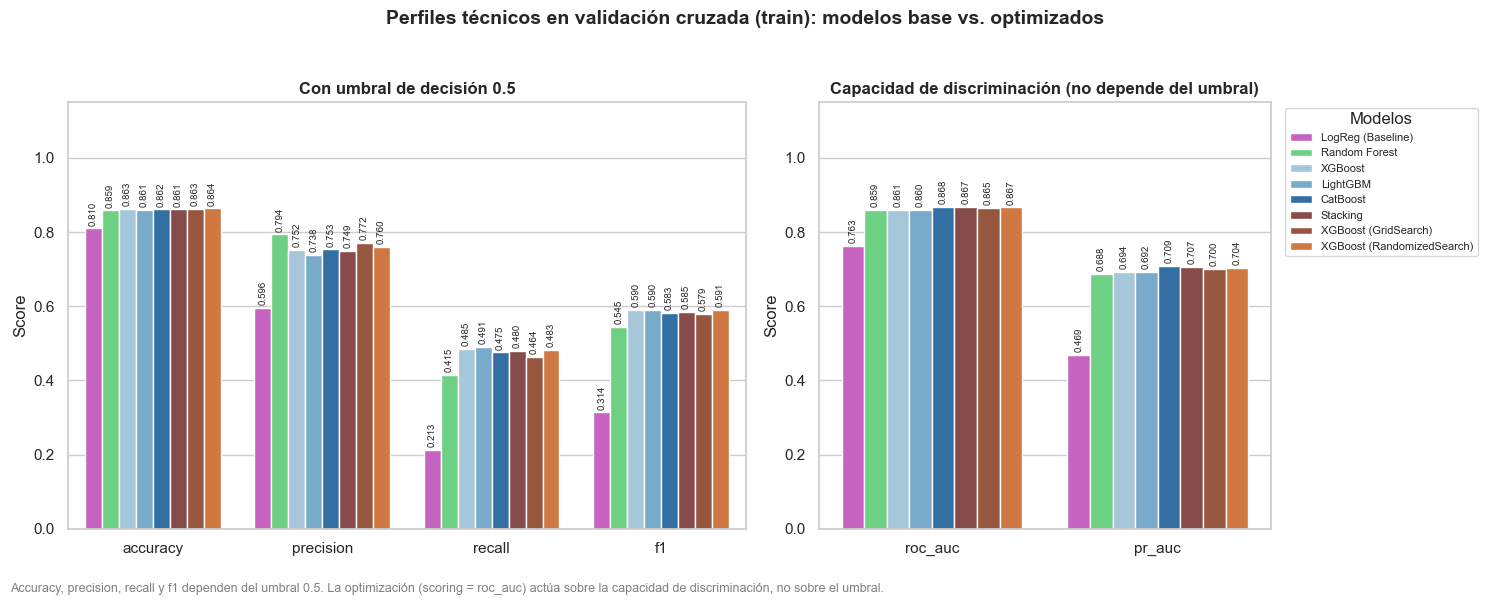

In [22]:

tabla_cv = pd.DataFrame(resultados_cv).T
tabla_cv.index = tabla_cv.index.str.replace("\n", " ", regex=False)
#print(list(tabla_cv.columns))
df_t = tabla_cv.copy()
df_t.index = df_t.index.str.replace("\n", " ", regex=False)
df_t = df_t.loc[[m for m in orden if m in df_t.index]]
paleta = {m: colores_limpios.get(m, "#999999") for m in df_t.index}

paneles = [
    (["accuracy", "precision", "recall", "f1"], "Con umbral de decisión 0.5"),
    (["roc_auc", "pr_auc"], "Capacidad de discriminación (no depende del umbral)"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, (mets, titulo) in zip(axes, paneles):
    d = (df_t[mets].rename_axis("Modelo").reset_index()
         .melt(id_vars="Modelo", var_name="Métrica", value_name="Score"))
    sns.barplot(ax=ax, data=d, x="Métrica", y="Score", hue="Modelo",
                hue_order=list(df_t.index), palette=paleta, legend=(ax is axes[1]))
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v:.3f}" for v in c.datavalues], fontsize=7, padding=2, rotation=90)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(""); ax.set_ylabel("Score"); ax.set_ylim(0, 1.15)

axes[1].legend(title="Modelos", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.suptitle("Perfiles técnicos en validación cruzada (train): modelos base vs. optimizados",
             fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Accuracy, precision, recall y f1 dependen del umbral 0.5. La optimización (scoring = roc_auc) actúa sobre la capacidad de discriminación, no sobre el umbral.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

### Elección entre GridSearchCV y RandomizedSearchCV

Las dos estrategias llevan a un resultado equivalente. En validación cruzada, el ROC-AUC es de 0,8646 con GridSearchCV y de 0,8666 con RandomizedSearchCV; la diferencia (0,002) es menor que el desvío entre folds (≈0,01). Ambas mejoran levemente al XGBoost sin ajustar (0,8609), y en ambas la profundidad óptima es 3.

Se elige **GridSearchCV**: explora de forma exhaustiva la grilla definida (8 combinaciones, 40 ajustes frente a los 60 de RandomizedSearchCV) y su resultado no depende de un muestreo aleatorio. La elección se hizo con la validación cruzada, no con el conjunto de test.


# 6. Evaluación final sobre el conjunto de prueba (test)

In [23]:
pipes_test = {
    nombre: Pipeline([("prep", preprocess), ("clf", mod)]).fit(X_train, y_train)
    for nombre, mod in modelos_base.items()
}
pipes_test["Stacking"] = pipe_stack.fit(X_train, y_train)
pipes_test["XGBoost (GridSearch)"] = mejor_pipe_xgb_grid
pipes_test["XGBoost (RandomizedSearch)"] = mejor_pipe_xgb_rand

resultados_test = {}
for nombre, pipe in pipes_test.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    resultados_test[nombre] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "pr_auc": average_precision_score(y_test, y_proba),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "business_metric": metrica_negocio_fun(y_test, y_pred, normalizar=False)
    }
    print(f"✅ {nombre} listo | ROC-AUC test: {resultados_test[nombre]['roc_auc']:.4f} ")

✅ LogReg (Baseline) listo | ROC-AUC test: 0.7748 
✅ Random Forest listo | ROC-AUC test: 0.8653 
✅ XGBoost listo | ROC-AUC test: 0.8645 
✅ LightGBM listo | ROC-AUC test: 0.8645 
✅ CatBoost listo | ROC-AUC test: 0.8699 
✅ Stacking listo | ROC-AUC test: 0.8699 
✅ XGBoost (GridSearch) listo | ROC-AUC test: 0.8685 
✅ XGBoost (RandomizedSearch) listo | ROC-AUC test: 0.8701 


## A) Tabla comparativa de métricas de rendimiento 

Esta es la tabla que responde la consigna: compara los ocho modelos (incluyendo XGBoost con y
sin tuning) sobre datos nunca vistos, ordenados por ROC-AUC de mayor a menor.

In [24]:
tabla_test = pd.DataFrame(resultados_test).T
tabla_test = tabla_test[["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc"]].round(4)
tabla_test = tabla_test.sort_values("roc_auc", ascending=False)
tabla_test

,accuracy,precision,recall,f1,pr_auc,roc_auc
XGBoost (RandomizedSearch),0.8700,0.8025,0.4791,0.6000,0.7195,0.8701
CatBoost,0.8740,0.8138,0.4939,0.6147,0.7265,0.8699
Stacking,0.8730,0.8048,0.4963,0.6140,0.7258,0.8699
XGBoost (GridSearch),0.8670,0.7743,0.4889,0.5994,0.7168,0.8685
Random Forest,0.8655,0.8286,0.4275,0.5640,0.7074,0.8653
XGBoost,0.8670,0.7701,0.4939,0.6018,0.7116,0.8645
LightGBM,0.8665,0.7846,0.4742,0.5911,0.7088,0.8645
LogReg (Baseline),0.8080,0.5891,0.1867,0.2836,0.4789,0.7748


## B) Gráfico comparativo de las métricas de rendimiento (test)

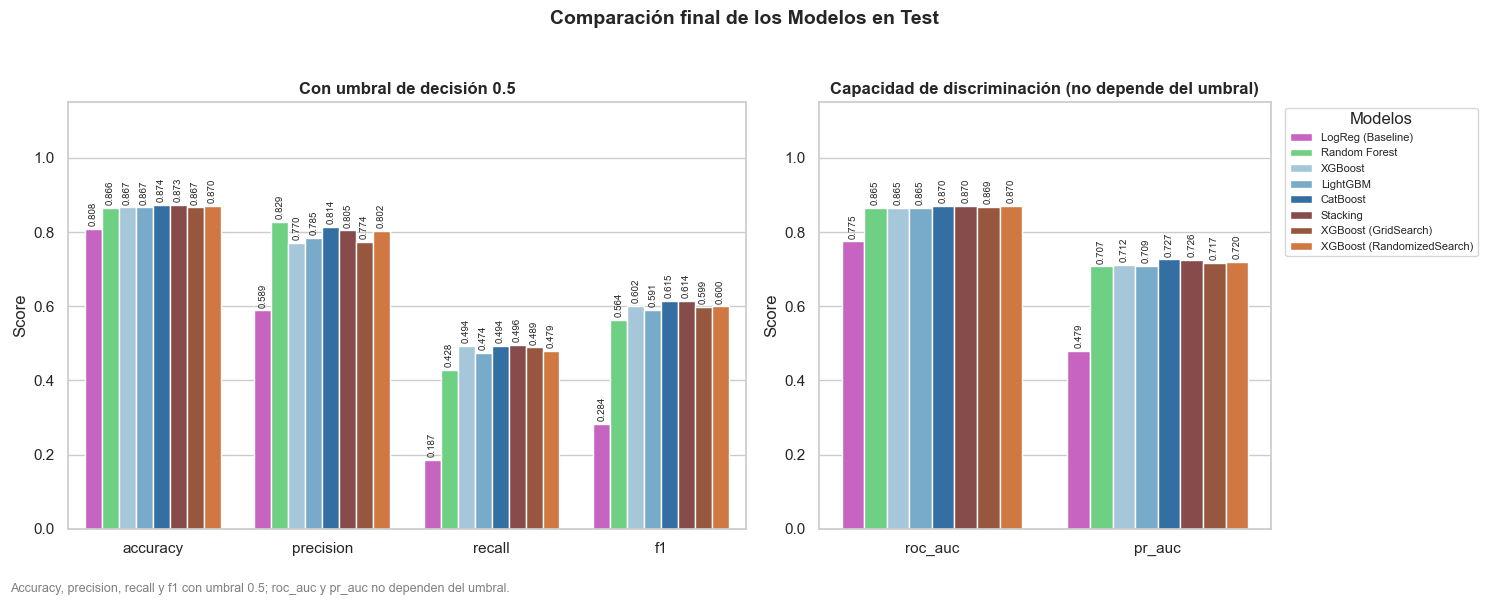

In [25]:
tabla_test = pd.DataFrame(resultados_test).T
tabla_test.index = tabla_test.index.str.replace("\n", " ", regex=False)
df_t = tabla_test.copy()
df_t.index = df_t.index.str.replace("\n", " ", regex=False)
df_t = df_t.loc[[m for m in orden if m in df_t.index]]
paleta = {m: colores_limpios.get(m, "#999999") for m in df_t.index}

paneles = [
    (["accuracy", "precision", "recall", "f1"], "Con umbral de decisión 0.5"),
    (["roc_auc", "pr_auc"], "Capacidad de discriminación (no depende del umbral)"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, (mets, titulo) in zip(axes, paneles):
    d = (df_t[mets].rename_axis("Modelo").reset_index()
         .melt(id_vars="Modelo", var_name="Métrica", value_name="Score"))
    sns.barplot(ax=ax, data=d, x="Métrica", y="Score", hue="Modelo",
                hue_order=list(df_t.index), palette=paleta, legend=(ax is axes[1]))
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v:.3f}" for v in c.datavalues], fontsize=7, padding=2, rotation=90)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(""); ax.set_ylabel("Score"); ax.set_ylim(0, 1.15)

axes[1].legend(title="Modelos", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.suptitle("Comparación final de los Modelos en Test",
             fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Accuracy, precision, recall y f1 con umbral 0.5; roc_auc y pr_auc no dependen del umbral.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

## C) Gráfico comparativo de la métrica de Negocio Personalizada (test)

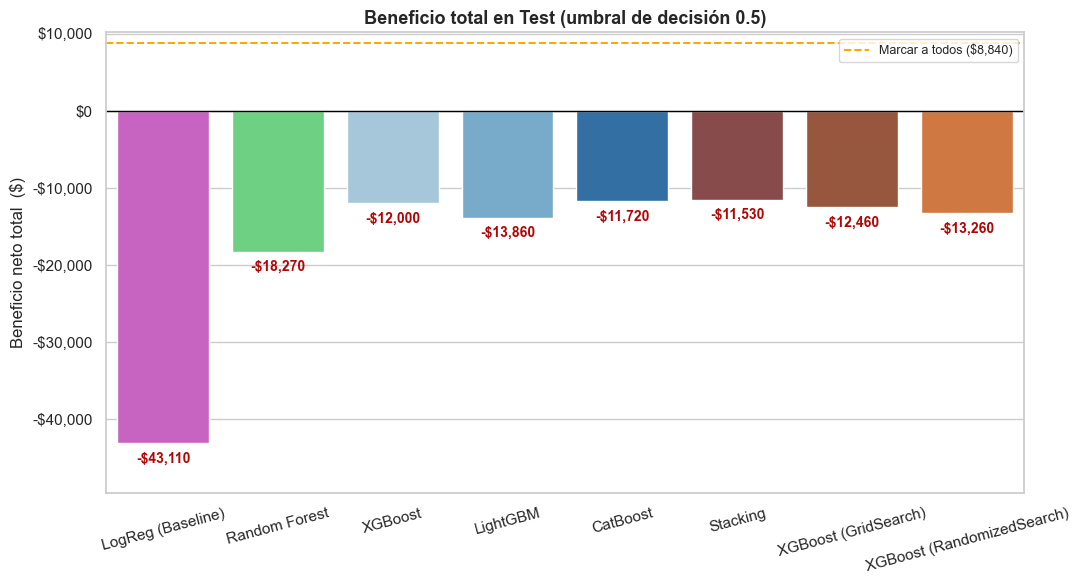

In [26]:
df_b = tabla_test.copy()
df_b.index = df_b.index.str.replace("\n", " ", regex=False)
df_b = df_b.sort_values("business_metric", ascending=False)
df_b = df_b.loc[[m for m in orden if m in df_b.index]]

colores_limpios = {k.replace("\n", " "): v for k, v in colores_estrategicos.items()}
paleta = {m: colores_limpios.get(m, "#999999") for m in df_b.index}

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(ax=ax, x=df_b.index, y=df_b["business_metric"],
            hue=df_b.index, palette=paleta, legend=False)

for p in ax.patches:
    h = p.get_height()
    if pd.notna(h):
        # etiquetas de las barras
        ax.annotate(fmt_usd(h), (p.get_x() + p.get_width() / 2., h),
            ha="center", va="top" if h < 0 else "bottom",
            fontsize=10, fontweight="bold",
            color="#b20606" if h < 0 else "#1a5f7a",   # rojo si es negativo, azul si es positivo
            xytext=(0, -6 if h < 0 else 6), textcoords="offset points")
ax.set_xticklabels([t.get_text().replace("Stacking (", "Stacking\n(") for t in ax.get_xticklabels()])      
ax.axhline(0, color="black", linewidth=1)
# referencia: marcar como positivo a todos los clientes (regla trivial)
ref_todos = metrica_negocio_fun(y_test, np.ones(len(y_test), dtype=int))
ax.axhline(ref_todos, color="orange", linestyle="--", linewidth=1.4, label=f"Marcar a todos ({fmt_usd(ref_todos)})")
ax.legend(loc="upper right", fontsize=9)
ax.set_ylim(min(df_b["business_metric"].min() * 1.15, 0), max(df_b["business_metric"].max() * 1.15, ref_todos * 1.15, 0))
ax.set_title("Beneficio total en Test (umbral de decisión 0.5)", fontsize=13, fontweight="bold")
ax.set_ylabel("Beneficio neto total  ($)")
ax.set_xlabel("")
# eje Y
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: fmt_usd(x)))
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

> **Cómo leer este gráfico:** igual que en validación cruzada, los montos corresponden al umbral por defecto (0.5), con el que se escapa más de la mitad de los positivos. Con ese corte ningún modelo supera siquiera a la regla trivial de marcar a todos los clientes (línea naranja). Miden el efecto del punto de corte y no la calidad de los modelos: al ajustar el umbral a los costos del negocio el resultado cambia (ver sección 7). Tampoco debe sorprender que el XGBoost optimizado no mejore aquí: se optimizó el ROC-AUC, que no depende del umbral.


# 7. Umbral de decisión óptimo según la métrica de negocio

Hasta acá todos los modelos se evaluaron con el umbral por defecto (0.5): un cliente se marca como "en riesgo" si su probabilidad de abandono es mayor o igual a 0,5. Ese corte no considera los costos del negocio: dejar escapar a un cliente que se va (falso negativo) cuesta 150, mientras que una falsa alarma cuesta 20. Con esos costos conviene marcar a más clientes, es decir, **bajar el umbral**. Como referencia, el umbral teórico es `costo_FP / (costo_FP + ganancia_TP + pérdida_FN)` = 20 / 270 ≈ 0,074 (vale si las probabilidades están calibradas).

**Método (el test no interviene en la decisión):**
1. Se obtienen probabilidades fuera de fold sobre train con el modelo elegido y la misma validación cruzada.
2. Se calcula el beneficio por cliente para cada umbral y se elige el que lo maximiza.
3. Una sola vez, se aplica ese umbral sobre test y se compara contra el umbral 0.5.

El ROC-AUC y el PR-AUC no dependen del umbral, por lo que los hiperparámetros elegidos con ROC-AUC no cambian; lo que cambia es el punto de corte con el que se usan las probabilidades.

## A) Cálculo del umbral óptimo (validación cruzada, train)

In [27]:
# --- Costos del negocio (los mismos de metrica_negocio_fun) ---
GANANCIA_TP, PERDIDA_FN, COSTO_FP = 100, 150, 20

def umbral_teorico(costo_fp=COSTO_FP, ganancia_tp=GANANCIA_TP, perdida_fn=PERDIDA_FN):
    """Se marca como positivo si p > costo_fp / (costo_fp + ganancia_tp + perdida_fn).
    Vale si las probabilidades del modelo están calibradas."""
    return costo_fp / (costo_fp + ganancia_tp + perdida_fn)

def curva_beneficio(y, p, umbrales, g=GANANCIA_TP, f=PERDIDA_FN, c=COSTO_FP):
    """Beneficio neto POR CLIENTE para cada umbral (positivo si p >= umbral)."""
    y = np.asarray(y).ravel()
    pos = int((y == 1).sum())
    out = []
    for t in umbrales:
        pred = p >= t
        tp = int((pred & (y == 1)).sum())
        fp = int(pred.sum()) - tp
        fn = pos - tp
        out.append((tp * g - fn * f - fp * c) / len(y))
    return np.array(out)

umbrales = np.linspace(0.01, 0.95, 95)
y_tr = np.asarray(y_train).ravel()

# Probabilidades fuera de fold con el modelo elegido (XGBoost optimizado con GridSearchCV)
p_oof = cross_val_predict(clone(mejor_pipe_xgb_grid), X_train, y_train, cv=cv,
                          method="predict_proba", n_jobs=-1)[:, 1]
curva_oof = curva_beneficio(y_tr, p_oof, umbrales)

i_opt = int(curva_oof.argmax())
UMBRAL_OPT = float(umbrales[i_opt])
ref_todos_tr = curva_beneficio(y_tr, np.ones(len(y_tr)), [0.5])[0]     # marcar a todos
ref_nada_tr = curva_beneficio(y_tr, np.zeros(len(y_tr)), [0.5])[0]     # no predecir nada
en_meseta = umbrales[curva_oof >= curva_oof.max() - 0.30]              # umbrales a menos de 0,30 del máximo

print(f"Umbral teórico:                {umbral_teorico():.3f}")
print(f"Umbral óptimo (CV, train):     {UMBRAL_OPT:.2f}  -> beneficio por cliente {curva_oof[i_opt]:.2f}")
print(f"Beneficio con umbral 0.50:     {curva_oof[np.argmin(np.abs(umbrales - 0.5))]:.2f}")
print(f"Meseta (a menos de 0,30 del máximo): {en_meseta.min():.2f} a {en_meseta.max():.2f}")
print(f"Marcar a todos: {ref_todos_tr:.2f} | No predecir nada: {ref_nada_tr:.2f}")


Umbral teórico:                0.074
Umbral óptimo (CV, train):     0.08  -> beneficio por cliente 8.61
Beneficio con umbral 0.50:     -7.50
Meseta (a menos de 0,30 del máximo): 0.06 a 0.09
Marcar a todos: 4.45 | No predecir nada: -30.56


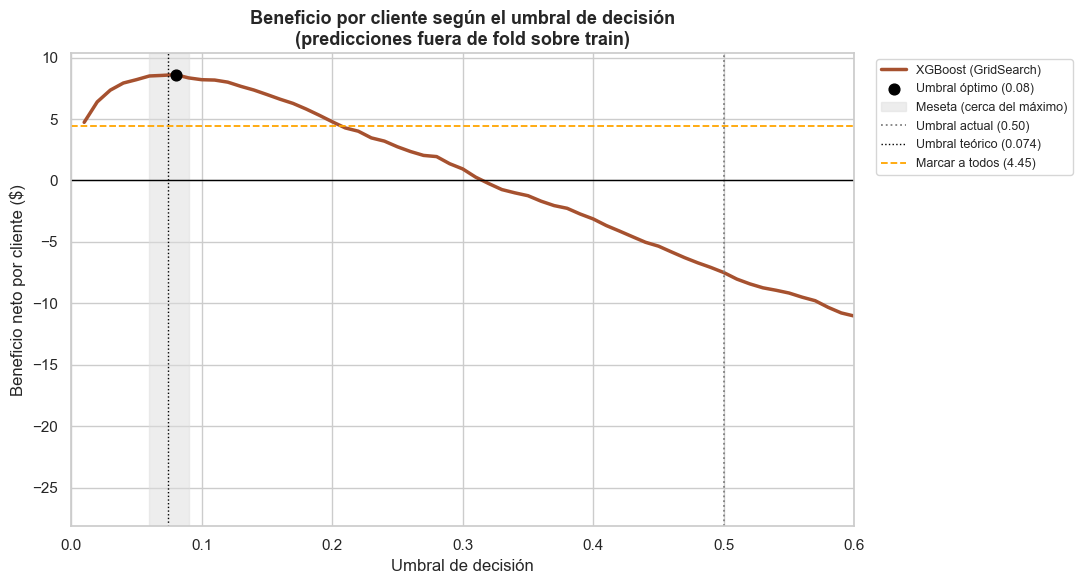

In [28]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(umbrales, curva_oof, color=colores_estrategicos["XGBoost (GridSearch)"], linewidth=2.5,
        label="XGBoost (GridSearch)")
ax.scatter(UMBRAL_OPT, curva_oof[i_opt], color="black", zorder=5, s=60, label=f"Umbral óptimo ({UMBRAL_OPT:.2f})")
ax.axvspan(en_meseta.min(), en_meseta.max(), color="#dddddd", alpha=0.5, label="Meseta (cerca del máximo)")
ax.axvline(0.5, color="gray", linestyle=":", linewidth=1.3, label="Umbral actual (0.50)")
ax.axvline(umbral_teorico(), color="black", linestyle=":", linewidth=1, label=f"Umbral teórico ({umbral_teorico():.3f})")
ax.axhline(ref_todos_tr, color="orange", linestyle="--", linewidth=1.3, label=f"Marcar a todos ({ref_todos_tr:.2f})")
ax.axhline(0, color="black", linewidth=1)

ax.set_xlim(0, 0.6)
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Beneficio neto por cliente ($)")
ax.set_title("Beneficio por cliente según el umbral de decisión\n(predicciones fuera de fold sobre train)",
             fontsize=13, fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


## B) Comparación en test: umbral 0.5 (actual) frente al umbral óptimo

Se aplica una sola vez el umbral elegido en validación cruzada sobre el conjunto de test. El ROC-AUC y el PR-AUC son los mismos con ambos umbrales; cambian las métricas que dependen del corte y, sobre todo, el resultado económico.

In [29]:
p_test = mejor_pipe_xgb_grid.predict_proba(X_test)[:, 1]
y_te = np.asarray(y_test).ravel()

def evaluar_umbral(t):
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
    return {
        "Clientes marcados (%)": 100 * pred.mean(),
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "Positivos detectados (TP)": tp,
        "Positivos que se escapan (FN)": fn,
        "Falsas alarmas (FP)": fp,
        "Beneficio total ($)": metrica_negocio_fun(y_te, pred),
        "Beneficio por cliente ($)": metrica_negocio_fun(y_te, pred, normalizar=True),
    }

col_5, col_opt = "Umbral 0.50 (actual)", f"Umbral óptimo ({UMBRAL_OPT:.2f})"
comparacion = pd.DataFrame({col_5: evaluar_umbral(0.5), col_opt: evaluar_umbral(UMBRAL_OPT)})

ref_todos_te = metrica_negocio_fun(y_te, np.ones(len(y_te), dtype=int), normalizar=True)
ref_nada_te = metrica_negocio_fun(y_te, np.zeros(len(y_te), dtype=int), normalizar=True)
print(f"Referencias en test (por cliente): marcar a todos {ref_todos_te:.2f} | no predecir nada {ref_nada_te:.2f}\n")

comparacion.round(3)


Referencias en test (por cliente): marcar a todos 4.42 | no predecir nada -30.52



,Umbral 0.50 (actual),Umbral óptimo (0.08)
Clientes marcados (%),12.850,59.600
Accuracy,0.867,0.582
Precision,0.774,0.320
Recall,0.489,0.936
F1,0.599,0.477
Positivos detectados (TP),199.000,381.000
Positivos que se escapan (FN),208.000,26.000
Falsas alarmas (FP),58.000,811.000
Beneficio total ($),-12460.000,17980.000
Beneficio por cliente ($),-6.230,8.990


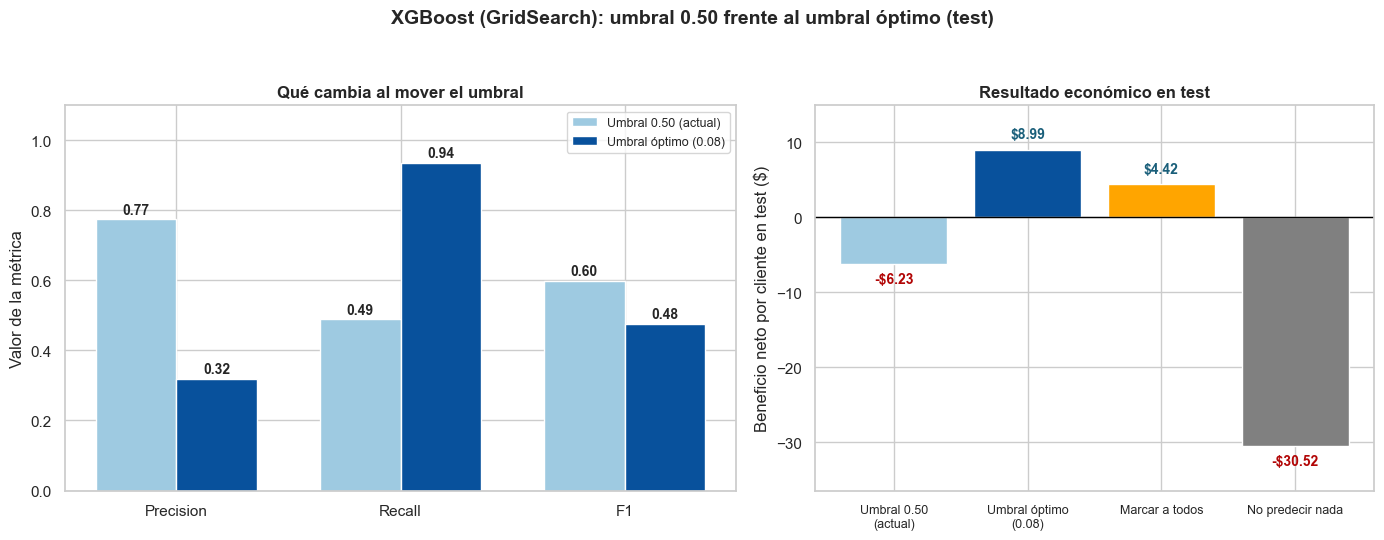

Beneficio por cliente: -6.23 (umbral 0.50) -> 8.99 (umbral 0.08); marcar a todos: 4.42.
Recall: 0.49 -> 0.94 | Precision: 0.77 -> 0.32 | Falsas alarmas: 58 -> 811


In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})

# --- Panel 1: precision, recall y F1 con cada umbral ---
mets = ["Precision", "Recall", "F1"]
x = np.arange(len(mets)); ancho = 0.36
for k, (col, color) in enumerate([(col_5, "#9ecae1"), (col_opt, "#08519c")]):
    barras = ax1.bar(x + (k - 0.5) * ancho, comparacion.loc[mets, col], ancho, color=color, label=col)
    ax1.bar_label(barras, fmt="%.2f", padding=2, fontsize=10, fontweight="bold")
ax1.set_xticks(x); ax1.set_xticklabels(mets)
ax1.set_ylim(0, 1.1); ax1.set_ylabel("Valor de la métrica")
ax1.set_title("Qué cambia al mover el umbral", fontsize=12, fontweight="bold")
ax1.legend(fontsize=9)

# --- Panel 2: beneficio por cliente en test ---
etiquetas = [col_5, col_opt, "Marcar a todos", "No predecir nada"]
valores = [comparacion.loc["Beneficio por cliente ($)", col_5], comparacion.loc["Beneficio por cliente ($)", col_opt],
           ref_todos_te, ref_nada_te]
colores = ["#9ecae1", "#08519c", "orange", "gray"]
barras = ax2.bar(range(4), valores, color=colores)
for b, v in zip(barras, valores):
    ax2.annotate(fmt_usd(v) if abs(v) >= 100 else (f"-${abs(v):.2f}" if v < 0 else f"${v:.2f}"),
                 (b.get_x() + b.get_width() / 2, v), ha="center", va="top" if v < 0 else "bottom",
                 xytext=(0, -6 if v < 0 else 6), textcoords="offset points",
                 fontsize=10, fontweight="bold", color="#b20606" if v < 0 else "#1a5f7a")
ax2.axhline(0, color="black", linewidth=1)
ax2.set_xticks(range(4)); ax2.set_xticklabels([e.replace(" (", "\n(") for e in etiquetas], fontsize=9)
ax2.set_ylabel("Beneficio neto por cliente en test ($)")
ax2.set_title("Resultado económico en test", fontsize=12, fontweight="bold")
lo, hi = min(valores + [0]), max(valores + [0]); m = (hi - lo) * 0.15
ax2.set_ylim(lo - m, hi + m)

fig.suptitle("XGBoost (GridSearch): umbral 0.50 frente al umbral óptimo (test)", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

print(f"Beneficio por cliente: {valores[0]:.2f} (umbral 0.50) -> {valores[1]:.2f} (umbral {UMBRAL_OPT:.2f}); "
      f"marcar a todos: {ref_todos_te:.2f}.")
print(f"Recall: {comparacion.loc['Recall', col_5]:.2f} -> {comparacion.loc['Recall', col_opt]:.2f} | "
      f"Precision: {comparacion.loc['Precision', col_5]:.2f} -> {comparacion.loc['Precision', col_opt]:.2f} | "
      f"Falsas alarmas: {int(comparacion.loc['Falsas alarmas (FP)', col_5])} -> {int(comparacion.loc['Falsas alarmas (FP)', col_opt])}")


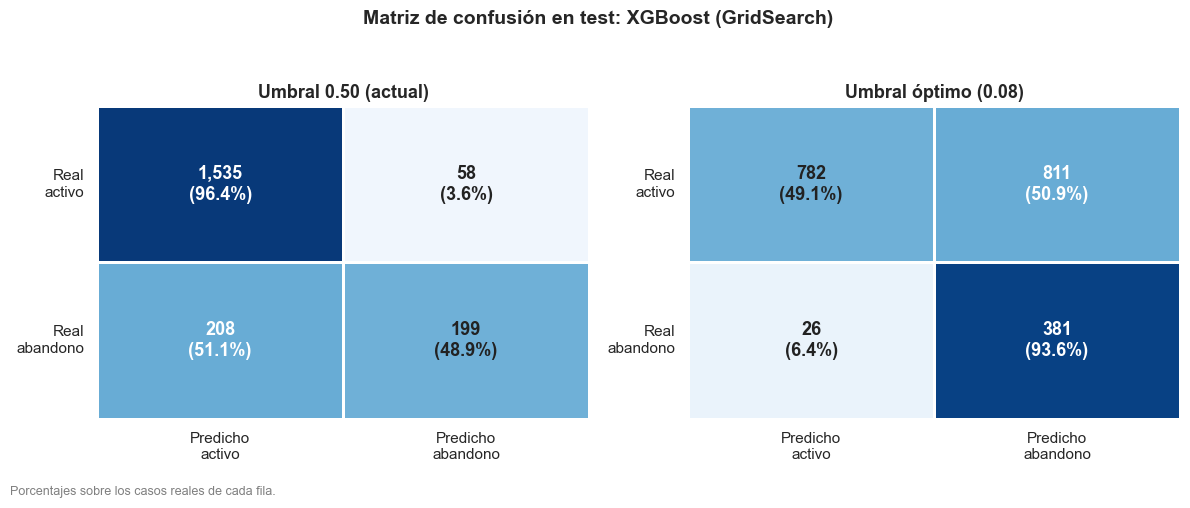

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (t, titulo) in zip(axes, [(0.5, "Umbral 0.50 (actual)"), (UMBRAL_OPT, f"Umbral óptimo ({UMBRAL_OPT:.2f})")]):
    pred = (p_test >= t).astype(int)
    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True)          # % sobre los casos reales de cada fila
    sns.heatmap(pct, cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=2, linecolor="white", ax=ax)
    for r in range(2):
        for c in range(2):
            ax.text(c + 0.5, r + 0.5, f"{cm[r, c]:,}\n({pct[r, c]:.1%})", ha="center", va="center",
                    fontsize=13, fontweight="bold", color="white" if pct[r, c] > 0.5 else "#222222")
    ax.set_xticklabels(["Predicho\nactivo", "Predicho\nabandono"])
    ax.set_yticklabels(["Real\nactivo", "Real\nabandono"], rotation=0)
    ax.set_title(titulo, fontsize=13, fontweight="bold")
fig.suptitle("Matriz de confusión en test: XGBoost (GridSearch)", fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Porcentajes sobre los casos reales de cada fila.", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.show()


**Cómo leer esta comparación.** Al bajar el umbral el modelo marca a más clientes: sube el *recall* (se detectan más abandonos) y baja la *precision* (aparecen más falsas alarmas). Lo que importa es el efecto neto con los costos del negocio, que mide el beneficio por cliente. El modelo solo aporta valor si, con el umbral elegido, supera a la regla trivial de **marcar a todos los clientes**. Las falsas alarmas tienen un costo real (contactar a un cliente que no se iba) y la ganancia depende de poder contactar a esa proporción de clientes; si el costo o la capacidad operativa cambian, el umbral debe recalcularse (ver la fórmula del umbral teórico).

## C) ¿Cambia la elección del modelo con el umbral óptimo?

Para cada modelo se calcula su propio umbral óptimo y su beneficio máximo con predicciones fuera de fold (train), y se compara contra la variabilidad entre folds. **Criterio:** si las diferencias de beneficio entre modelos son menores que el desvío entre folds, los modelos son equivalentes también en términos de negocio y la elección de XGBoost (y de GridSearchCV) se mantiene por los criterios ya explicados. Solo cambiaría si algún modelo superara a XGBoost por un margen claramente mayor que ese desvío.

In [35]:
candidatos = {n: Pipeline([("prep", preprocess), ("clf", m)]) for n, m in modelos_base.items()}
candidatos["Stacking"] = pipe_stack
candidatos["XGBoost (GridSearch)"] = mejor_pipe_xgb_grid
candidatos["XGBoost (RandomizedSearch)"] = mejor_pipe_xgb_rand

filas, curvas_oof = {}, {}
for nombre, pipe in candidatos.items():
    p = cross_val_predict(clone(pipe), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    c = curva_beneficio(y_tr, p, umbrales)
    j = int(c.argmax()); t = float(umbrales[j])
    # beneficio por fold con el umbral óptimo del modelo -> desvío entre folds
    por_fold = [curva_beneficio(y_tr[idx], p[idx], [t])[0] for _, idx in cv.split(X_train, y_tr)]
    curvas_oof[nombre] = c
    filas[nombre] = {
        "umbral_optimo": t,
        "beneficio_pico": c[j],
        "desvio_folds": float(np.std(por_fold, ddof=1)),
        f"beneficio @{UMBRAL_OPT:.2f}": curva_beneficio(y_tr, p, [UMBRAL_OPT])[0],
        "roc_auc_oof": roc_auc_score(y_tr, p),
    }
    print(f"✅ {nombre} listo")

tabla_umbral = pd.DataFrame(filas).T.sort_values("beneficio_pico", ascending=False)
tabla_umbral["vs. marcar a todos"] = tabla_umbral["beneficio_pico"] - ref_todos_tr
print(f"\nReferencia (train): marcar a todos {ref_todos_tr:.2f} | no predecir nada {ref_nada_tr:.2f}\n")
tabla_umbral.round(3)


✅ LogReg (Baseline) listo
✅ Random Forest listo
✅ XGBoost listo
✅ LightGBM listo
✅ CatBoost listo
✅ Stacking listo
✅ XGBoost (GridSearch) listo
✅ XGBoost (RandomizedSearch) listo

Referencia (train): marcar a todos 4.45 | no predecir nada -30.56



,umbral_optimo,beneficio_pico,desvio_folds,beneficio @0.08,roc_auc_oof,vs. marcar a todos
XGBoost (RandomizedSearch),0.07,8.755,0.505,8.441,0.866,4.305
Stacking,0.07,8.739,0.606,8.511,0.867,4.289
CatBoost,0.06,8.719,0.724,8.422,0.868,4.269
XGBoost (GridSearch),0.08,8.612,0.476,8.612,0.864,4.163
XGBoost,0.06,8.520,0.560,7.941,0.861,4.070
LightGBM,0.06,8.410,0.608,8.266,0.860,3.960
Random Forest,0.10,8.245,0.341,8.159,0.859,3.795
LogReg (Baseline),0.06,5.832,0.663,5.756,0.762,1.382


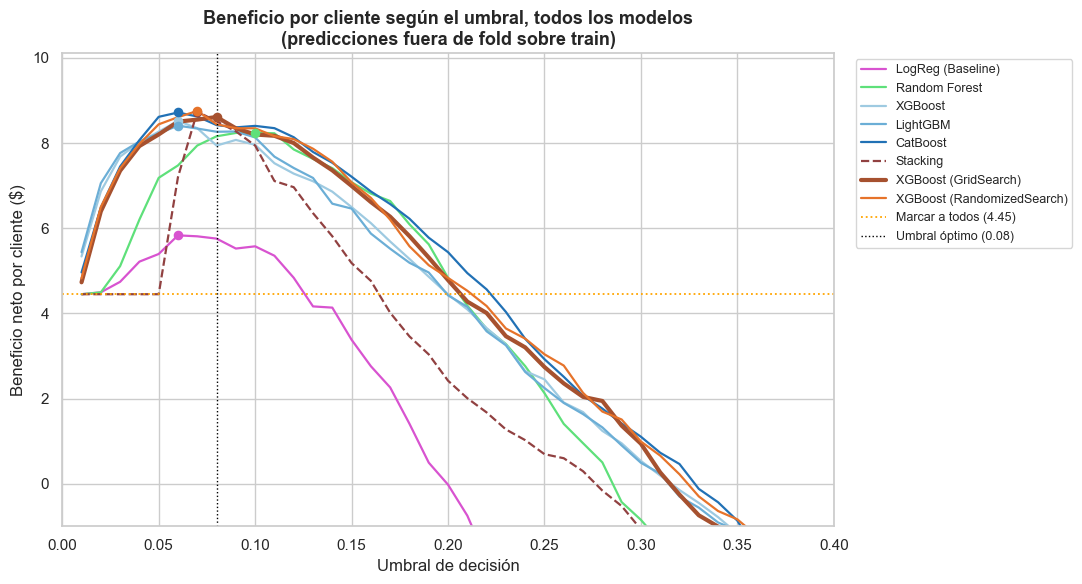

In [36]:
colores_limpios = {k.replace("\n", " "): v for k, v in colores_estrategicos.items()}

fig, ax = plt.subplots(figsize=(11, 6))
for nombre, c in curvas_oof.items():
    es_xgb = nombre == "XGBoost (GridSearch)"
    ax.plot(umbrales, c, label=nombre, color=colores_limpios.get(nombre, "#999999"),
            linewidth=3 if es_xgb else 1.6, linestyle="-" if es_xgb else "--" if nombre == "Stacking" else "-")
    j = int(c.argmax()); ax.scatter(umbrales[j], c[j], color=colores_limpios.get(nombre, "#999999"), s=35, zorder=5)
ax.axhline(ref_todos_tr, color="orange", linestyle=":", linewidth=1.3, label=f"Marcar a todos ({ref_todos_tr:.2f})")
ax.axvline(UMBRAL_OPT, color="black", linestyle=":", linewidth=1, label=f"Umbral óptimo ({UMBRAL_OPT:.2f})")
ax.set_xlim(0, 0.4)
ax.set_ylim(min(0, ref_todos_tr) - 1, curva_oof.max() + 1.5)
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Beneficio neto por cliente ($)")
ax.set_title("Beneficio por cliente según el umbral, todos los modelos\n(predicciones fuera de fold sobre train)",
             fontsize=13, fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


**Cómo leer la tabla y el gráfico.** `beneficio_pico` es el beneficio por cliente de cada modelo con su propio umbral óptimo, y `desvio_folds` mide cuánto varía ese beneficio entre los 5 folds. Si la diferencia entre XGBoost (GridSearch) y los demás boostings es menor que ese desvío, no hay evidencia de que otro modelo sea mejor en términos de negocio. La regresión logística, en cambio, sí debería quedar claramente por debajo. Como cada modelo usa su propio umbral elegido sobre los mismos datos, los picos son levemente optimistas, pero la comparación es pareja para todos.


## D) Incertidumbre del resultado en test (bootstrap)

El beneficio por cliente en test es un número puntual calculado sobre 2.000 clientes, de los cuales solo 407 abandonan, y cada abandono no detectado pesa 150. Para medir cuánto puede variar, se **remuestrean con reposición los clientes del conjunto de test** (2.000 repeticiones) y se recalcula el beneficio de cada estrategia sobre **los mismos clientes remuestreados** (comparación pareada). Se informa el intervalo de confianza al 95 % (percentiles 2,5 y 97,5). No se reentrena ningún modelo y el umbral no se modifica.

In [37]:
# Bootstrap sobre las filas de test (mismas filas para todas las estrategias)
N_BOOT = 2000
rng = np.random.default_rng(RANDOM_STATE)
n_te = len(y_te)

def beneficio_cliente(y, pred):
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    return (tp * GANANCIA_TP - fn * PERDIDA_FN - fp * COSTO_FP) / len(y)

estrategias = {
    "Umbral 0.50": (p_test >= 0.5).astype(int),
    f"Umbral óptimo ({UMBRAL_OPT:.2f})": (p_test >= UMBRAL_OPT).astype(int),
    "Marcar a todos": np.ones(n_te, dtype=int),
}
nombres_e = list(estrategias)
boot = {k: np.empty(N_BOOT) for k in estrategias}
for b in range(N_BOOT):
    idx = rng.integers(0, n_te, n_te)
    for k, pred in estrategias.items():
        boot[k][b] = beneficio_cliente(y_te[idx], pred[idx])

obs_e = {k: beneficio_cliente(y_te, pred) for k, pred in estrategias.items()}
dif_nombres = {f"{nombres_e[1]} − umbral 0.50": (nombres_e[1], nombres_e[0]),
               f"{nombres_e[1]} − marcar a todos": (nombres_e[1], nombres_e[2])}
filas = []
for k in nombres_e:
    lo, hi = np.percentile(boot[k], [2.5, 97.5])
    filas.append({"Estrategia": k, "Observado ($/cliente)": obs_e[k], "IC 95% inf": lo, "IC 95% sup": hi})
for k, (a, b_) in dif_nombres.items():
    d = boot[a] - boot[b_]; lo, hi = np.percentile(d, [2.5, 97.5])
    filas.append({"Estrategia": k, "Observado ($/cliente)": obs_e[a] - obs_e[b_], "IC 95% inf": lo, "IC 95% sup": hi})
tabla_boot = pd.DataFrame(filas).set_index("Estrategia")
tabla_boot.round(2)


,Observado ($/cliente),IC 95% inf,IC 95% sup
Estrategia,,,
Umbral 0.50,-6.23,-8.90,-3.69
Umbral óptimo (0.08),8.99,7.08,11.24
Marcar a todos,4.42,2.50,6.70
Umbral óptimo (0.08) − umbral 0.50,15.22,12.02,18.55
Umbral óptimo (0.08) − marcar a todos,4.57,3.19,5.79


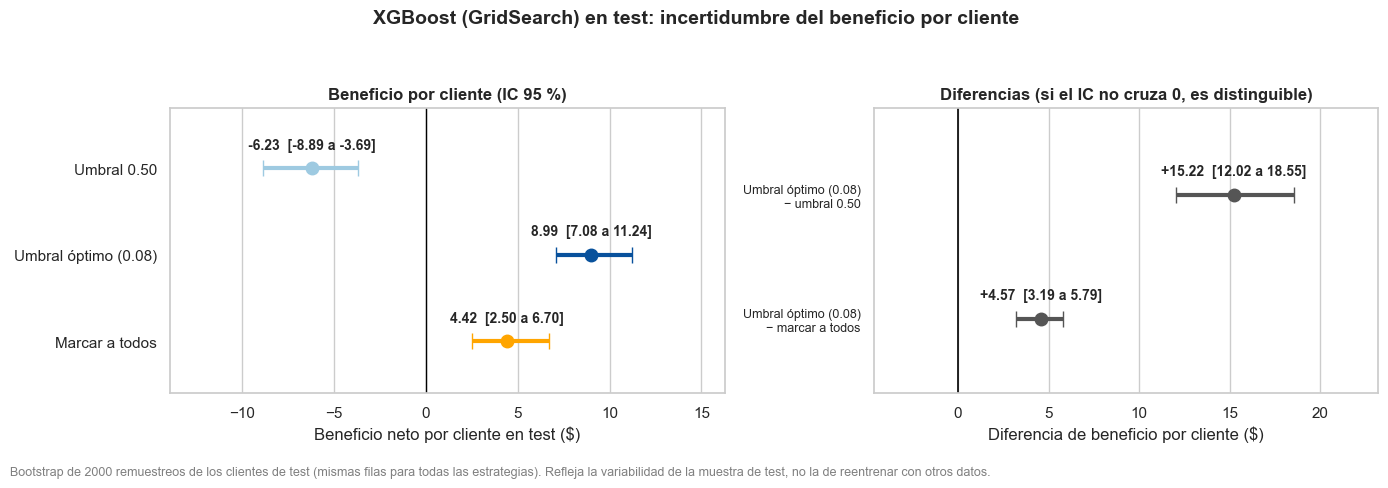

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
colores_b = ["#9ecae1", "#08519c", "orange"]

# --- Panel 1: beneficio por cliente de cada estrategia ---
for i, k in enumerate(nombres_e):
    fila = tabla_boot.loc[k]
    ax1.errorbar(fila["Observado ($/cliente)"], i,
                 xerr=[[fila["Observado ($/cliente)"] - fila["IC 95% inf"]], [fila["IC 95% sup"] - fila["Observado ($/cliente)"]]],
                 fmt="o", color=colores_b[i], ecolor=colores_b[i], capsize=6, markersize=9, elinewidth=3)
    ax1.annotate(f"{fila['Observado ($/cliente)']:.2f}  [{fila['IC 95% inf']:.2f} a {fila['IC 95% sup']:.2f}]",
                 (fila["Observado ($/cliente)"], i), xytext=(0, 14), textcoords="offset points",
                 ha="center", fontsize=10, fontweight="bold")
ax1.axvline(0, color="black", linewidth=1)
ax1.set_yticks(range(len(nombres_e))); ax1.set_yticklabels(nombres_e); ax1.invert_yaxis()
ax1.set_ylim(len(nombres_e) - 0.4, -0.7)
ax1.set_xlabel("Beneficio neto por cliente en test ($)")
ax1.set_title("Beneficio por cliente (IC 95 %)", fontsize=12, fontweight="bold")
ax1.grid(axis="y", visible=False)
ax1.margins(x=0.25)

# --- Panel 2: diferencias entre estrategias ---
for i, k in enumerate(dif_nombres):
    fila = tabla_boot.loc[k]
    ax2.errorbar(fila["Observado ($/cliente)"], i,
                 xerr=[[fila["Observado ($/cliente)"] - fila["IC 95% inf"]], [fila["IC 95% sup"] - fila["Observado ($/cliente)"]]],
                 fmt="o", color="#555555", capsize=6, markersize=9, elinewidth=3)
    ax2.annotate(f"{fila['Observado ($/cliente)']:+.2f}  [{fila['IC 95% inf']:.2f} a {fila['IC 95% sup']:.2f}]",
                 (fila["Observado ($/cliente)"], i), xytext=(0, 14), textcoords="offset points",
                 ha="center", fontsize=10, fontweight="bold")
ax2.axvline(0, color="black", linewidth=1.2)
ax2.set_yticks(range(len(dif_nombres)))
ax2.set_yticklabels([k.replace(" − ", "\n− ") for k in dif_nombres], fontsize=9); ax2.invert_yaxis()
ax2.set_ylim(len(dif_nombres) - 0.4, -0.7)
ax2.set_xlabel("Diferencia de beneficio por cliente ($)")
ax2.set_title("Diferencias (si el IC no cruza 0, es distinguible)", fontsize=12, fontweight="bold")
ax2.grid(axis="y", visible=False)
ax2.margins(x=0.25)

fig.suptitle("XGBoost (GridSearch) en test: incertidumbre del beneficio por cliente", fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, f"Bootstrap de {N_BOOT} remuestreos de los clientes de test (mismas filas para todas las estrategias). "
         "Refleja la variabilidad de la muestra de test, no la de reentrenar con otros datos.", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.04, 1, 0.93])
plt.show()


**Cómo leer estos intervalos.** Si el intervalo de la diferencia *umbral óptimo − marcar a todos* queda por encima de cero, el modelo con el umbral elegido aporta valor sobre la regla trivial de forma consistente y no por azar de la muestra. Si el intervalo de *umbral óptimo − umbral 0.50* queda por encima de cero, el ajuste del umbral mejora el resultado de manera distinguible. Los intervalos son anchos porque hay pocos abandonos y cada uno pesa mucho en el beneficio.

## E) Desempeño por grupo (Geografía y Género)

`Geography` y `Gender` son entradas del modelo. Con el umbral óptimo se compara, para cada grupo del conjunto de test, el ***recall*** (proporción de abandonos detectados), la **tasa de falsas alarmas** (proporción de clientes que no abandonan y reciben una alerta) y el beneficio por cliente. Las proporciones se acompañan con intervalos de confianza de Wilson al 95 %. Es un análisis descriptivo sobre el conjunto de test.

In [39]:
# Grupos a partir de las dummies de X_test (referencias: Francia y mujer)
geografia = np.select([X_test["Geography_Germany"] == 1, X_test["Geography_Spain"] == 1], ["Alemania", "España"], default="Francia")
genero = np.where(X_test["Gender_Male"] == 1, "Hombre", "Mujer")
variables_grupo = {"Geografía": geografia, "Género": genero}

def wilson(k, n, z=1.96):
    """Intervalo de confianza de Wilson para una proporción k/n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - margen, centro + margen

def metricas_grupo(mask, t):
    y = y_te[mask]
    pred = (p_test[mask] >= t).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    r_lo, r_hi = wilson(tp, tp + fn); f_lo, f_hi = wilson(fp, fp + tn)
    return {"n": len(y), "abandonos reales": tp + fn, "abandono real (%)": 100 * y.mean(), "marcados (%)": 100 * pred.mean(),
            "recall": tp / (tp + fn) if tp + fn else np.nan, "recall_lo": r_lo, "recall_hi": r_hi,
            "fpr": fp / (fp + tn) if fp + tn else np.nan, "fpr_lo": f_lo, "fpr_hi": f_hi,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "beneficio por cliente ($)": beneficio_cliente(y, pred)}

def tabla_por_grupo(t):
    filas = []
    for var, etiquetas in variables_grupo.items():
        for g in sorted(pd.unique(etiquetas)):
            f = {"Variable": var, "Grupo": g}; f.update(metricas_grupo(etiquetas == g, t)); filas.append(f)
    return pd.DataFrame(filas).set_index(["Variable", "Grupo"])

tabla_grupos = tabla_por_grupo(UMBRAL_OPT)
tabla_grupos_05 = tabla_por_grupo(0.5)

print(f"--- Umbral óptimo ({UMBRAL_OPT:.2f}) ---")
print(tabla_grupos[["n", "abandonos reales", "abandono real (%)", "marcados (%)", "recall", "fpr", "precision", "beneficio por cliente ($)"]].round(3).to_string())
print("\n--- Umbral 0.50 (para comparar) ---")
print(tabla_grupos_05[["recall", "fpr", "precision", "beneficio por cliente ($)"]].round(3).to_string())


--- Umbral óptimo (0.08) ---
                       n  abandonos reales  abandono real (%)  marcados (%)  recall    fpr  precision  beneficio por cliente ($)
Variable  Grupo                                                                                                                 
Geografía Alemania   504               151             29.960        82.937   0.980  0.765      0.354                     17.758
          España     475                81             17.053        55.579   0.926  0.480      0.284                      5.937
          Francia   1021               175             17.140        49.951   0.903  0.416      0.310                      6.082
Género    Hombre    1070               174             16.262        53.271   0.902  0.461      0.275                      4.570
          Mujer      930               233             25.054        66.882   0.961  0.571      0.360                     14.075

--- Umbral 0.50 (para comparar) ---
                    recall    f

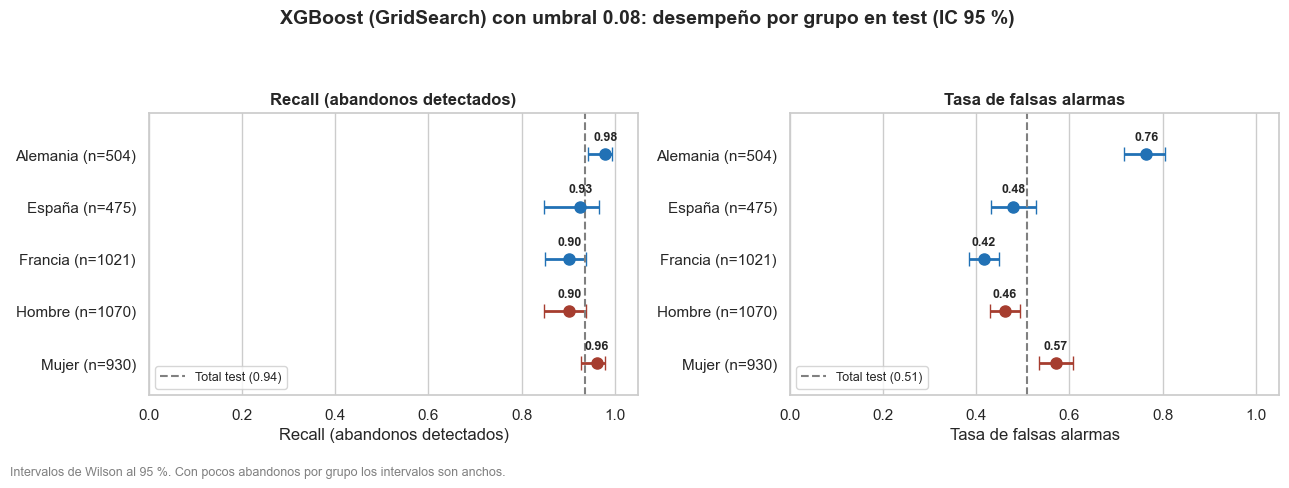

In [40]:
orden_g = [("Geografía", "Alemania"), ("Geografía", "España"), ("Geografía", "Francia"), ("Género", "Hombre"), ("Género", "Mujer")]
orden_g = [g for g in orden_g if g in tabla_grupos.index]
colores_g = {"Geografía": "#2171b5", "Género": "#a63d2f"}

pred_tot = (p_test >= UMBRAL_OPT).astype(int)
rec_global = ((pred_tot == 1) & (y_te == 1)).sum() / (y_te == 1).sum()
fpr_global = ((pred_tot == 1) & (y_te == 0)).sum() / (y_te == 0).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (col, titulo, glob) in zip(axes, [("recall", "Recall (abandonos detectados)", rec_global),
                                           ("fpr", "Tasa de falsas alarmas", fpr_global)]):
    for k, (var, g) in enumerate(orden_g):
        fila = tabla_grupos.loc[(var, g)]
        ax.errorbar(fila[col], k, xerr=[[fila[col] - fila[col + "_lo"]], [fila[col + "_hi"] - fila[col]]],
                    fmt="o", color=colores_g[var], capsize=5, markersize=8, elinewidth=2)
        ax.annotate(f"{fila[col]:.2f}", (fila[col], k), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=9, fontweight="bold")
    ax.axvline(glob, color="gray", linestyle="--", label=f"Total test ({glob:.2f})")
    ax.set_yticks(range(len(orden_g)))
    ax.set_yticklabels([f"{g} (n={int(tabla_grupos.loc[(v, g), 'n'])})" for v, g in orden_g])
    ax.invert_yaxis(); ax.set_xlim(0, 1.05); ax.set_ylim(len(orden_g) - 0.4, -0.8)
    ax.set_xlabel(titulo); ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.legend(fontsize=9, loc="lower left"); ax.grid(axis="y", visible=False)

fig.suptitle(f"XGBoost (GridSearch) con umbral {UMBRAL_OPT:.2f}: desempeño por grupo en test (IC 95 %)", fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Intervalos de Wilson al 95 %. Con pocos abandonos por grupo los intervalos son anchos.", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.04, 1, 0.92])
plt.show()


**Cómo leer el análisis por grupo.** Las diferencias de *recall* o de falsas alarmas entre grupos solo son relevantes si los intervalos no se solapan; con pocos abandonos por grupo (por ejemplo en España) los intervalos son anchos. El porcentaje de clientes marcados y la precisión dependen de la tasa de abandono de cada grupo (en Alemania es casi el doble que en Francia y España), por lo que pueden diferir aun con un mismo umbral sin que eso implique, por sí solo, un trato desigual del modelo. Si se detectara una diferencia clara de *recall* o de falsas alarmas, conviene revisar si `Geography` y `Gender` deben seguir siendo entradas del modelo o si los costos de intervención difieren por grupo. Este análisis es descriptivo y no sustituye una evaluación legal o regulatoria.

---

# 8. Importancia de variables en el XGBoost optimizado

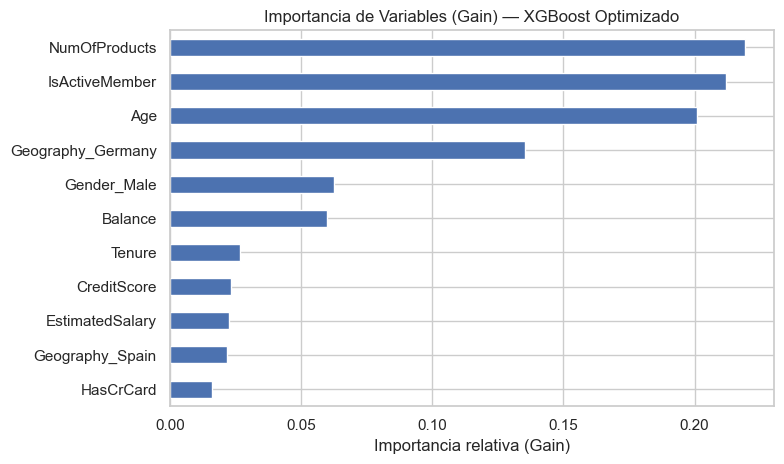

In [41]:
nombres_features = mejor_pipe_xgb_grid.named_steps["prep"].get_feature_names_out()
nombres_limpios = [n.split("__")[-1] for n in nombres_features]
importancias_xgb = pd.Series(
    mejor_pipe_xgb_grid.named_steps["clf"].feature_importances_,
    index=nombres_limpios
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.8))
importancias_xgb.plot(kind="barh", color="#4C72B0", ax=ax)
ax.set_title("Importancia de Variables (Gain) — XGBoost Optimizado")
ax.set_xlabel("Importancia relativa (Gain)")
plt.tight_layout()
plt.show()

> **Cómo leer la importancia de variables:** la importancia por *gain* indica cuánto utiliza el modelo cada variable para dividir los árboles; no indica causalidad ni el sentido del efecto, y cuando hay variables correlacionadas (por ejemplo `Balance` y `Geography_Germany`) la importancia se reparte de forma arbitraria. Para la dirección del efecto conviene contrastarla con los odds ratios del 1er avance. Una alternativa más robusta es la importancia por permutación sobre el conjunto de test.


# 9 Conclusión y recomendación

**Mejora respecto al Avance 1.** Al pasar de la regresión logística baseline a modelos de Gradient Boosting y Stacking, el ROC-AUC en test sube de 0,775 a ~0,870 (+9,5 puntos porcentuales), el PR-AUC de 0,479 a ~0,71–0,73 (+23 a +25 puntos) y el F1-Score de 0,284 a ~0,59–0,61 (se duplica la efectividad en la detección de fugas con el umbral estándar). Todos los modelos usan las mismas variables, incluidas `Geography_Germany`, `Geography_Spain` y `Gender_Male`, por lo que la comparación es pareja.

**Impacto del ajuste de hiperparámetros.** Optimizar XGBoost con GridSearchCV (reduciendo `max_depth` de 4 a 3, `learning_rate` a 0,05 y con 300 árboles) llevó su ROC-AUC en validación cruzada de 0,8609 a 0,8646 y, en test, de 0,8645 a 0,8685. Es una mejora leve (+0,004), menor que el desvío entre folds (≈0,011), y deja al XGBoost optimizado a la par de CatBoost y del Stacking. RandomizedSearchCV llegó a un resultado equivalente (0,8666 en CV y 0,8701 en test); se eligió GridSearchCV por explorar de forma exhaustiva la grilla definida y por requerir menos ajustes (40 frente a 60).

**Selección del modelo.** XGBoost, LightGBM y CatBoost rinden de forma equivalente y con costos de entrenamiento bajos; el Stacking tarda unas 20 veces más que XGBoost sin una mejora distinguible. Se seleccionó XGBoost entre las alternativas equivalentes.

**Impacto económico y umbral de decisión.** Con el umbral estándar (0.5) todos los modelos arrojan pérdidas con la métrica de negocio (+100 por acierto, −150 por positivo no detectado, −20 por falsa alarma) y ninguno supera a la regla de marcar a todos los clientes, porque detectan menos de la mitad de las fugas. En la sección 7 se calculó el umbral óptimo con validación cruzada sobre train y se lo confirmó una sola vez en test; con el XGBoost optimizado, el beneficio por cliente en test pasa de −6,23 con el umbral 0.5 a +8,99 con el umbral óptimo (0,08), frente a 4,42 de marcar a todos; el recall sube de 0,49 a 0,94 a cambio de pasar de 58 a 811 falsas alarmas (la precisión baja de 0,77 a 0,32). La verificación de que la elección del modelo se mantiene con el umbral óptimo (7C), la incertidumbre de estos resultados (7D) y el desempeño por grupo (7E) están en esa sección. El umbral debe recalcularse si cambian los costos.

**Recomendación de despliegue.**
- Si FinanceGuard busca máxima discriminación, el Stacking (ROC-AUC ≈ 0.870), CatBoost y XGBoost (GridSearch) (≈ 0.869–0.870) rinden de forma equivalente: las diferencias son de milésimas.
- Si se pondera simplicidad operativa y mantenimiento en producción, recomendamos desplegar XGBoost (GridSearch) como modelo único, con el umbral óptimo de la sección 7: logra prácticamente el mismo desempeño que el Stacking con un único artefacto liviano y mucho más barato de entrenar y mantener.

**Limitaciones.** Los resultados dependen de los costos asumidos; si cambian, el umbral debe recalcularse. Como `Geography` y `Gender` son entradas del modelo, si las predicciones se usan para tratar de forma distinta a los clientes (por ejemplo, ofertas de retención), conviene revisar el desempeño por grupo (sección 7E). El conjunto de test se usó como confirmación final y no para seleccionar el modelo ni el umbral.
